# Explication du projet

Pour atteindre son objectif de ville neutre en émissions de carbone en 2050, la ville de Seattle souhaite étudier finement la consommation ainsi que les émissions des bâtiments non destinés à l’habitation. L'objectif principal sera de prédire ces deux variables à partir de données structurelles liées aux batiments. Un objectif secondaire sera d'étudier l'impact de la variable EnergyStar sur les résultats de prédictions afin de déterminer s'il est nécéssaire de continuer à calculer ce score. Le présent notebook sera dédié à la prédiction de la variable <u>'SiteEnergyUse(kBtu)'<u>

# Sommaire

- [3 Import](#Import-des-bibliothèques-et-des-données)
- [4 Prétraitement général](#Prétraitement-général)
- [5 Séparation des données ](#Séparation-des-données )
- [6 Feature engineering](#Feature-engineering)
- [7 Fonctions d'évaluation de la performance du modèle](#Fonctions-d'évaluation-de-la-performance-du-modèle)
- [8 Préprocessing des données](#Préprocessing)
- [9 Premier modele : LinearRegression](#Premier-modele:-LinearRegression)
- [10 Autres modèles](#Autres-modèles)
- [11 Modification du préprocessing](#Modification-du-préprocessing)
- [12 Optimisations](#Optimisation)
- [13 Impact ENERGYStar](#Impact-ENERGYStar)
- [14 Evaluation détaillée du modèle final](#Evaluation-détaillée-du-modele-final)
- [15 Conclusions](#Conclusions)

# Import des bibliothèques et des données

**Bibliothèques**

In [1]:
# Manipulation de données
import pandas as pd
import missingno as msno
import numpy as np

# Représentation graphique
import matplotlib.pyplot as plt
import seaborn as sns
from plotnine import *

# Explicativité modèle
import shap 

# Librairie sickit learn
from sklearn.model_selection import train_test_split, learning_curve, cross_val_score, KFold, GridSearchCV, StratifiedKFold, RandomizedSearchCV,  RepeatedStratifiedKFold
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import RobustScaler, MinMaxScaler, OneHotEncoder, PolynomialFeatures, StandardScaler, OrdinalEncoder, TargetEncoder
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet
from sklearn.metrics import mean_absolute_error
from sklearn.feature_selection import SelectKBest, f_regression, SelectFromModel
from sklearn.compose import ColumnTransformer,TransformedTargetRegressor
from sklearn.preprocessing import MinMaxScaler,  FunctionTransformer, PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, HistGradientBoostingRegressor, AdaBoostRegressor,GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_percentage_error, r2_score, mean_absolute_error,  make_scorer, root_mean_squared_error
from sklearn.svm import SVR
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyRegressor

# Modèle hors scikit learn
from xgboost import XGBRegressor

# Gestion de certains warnings
import warnings

# Calcul temps d'execution
import time

**Données**

In [2]:
# Import du jeu de données obtenu lors du notebook d'exploration et de nettoyage
Data = pd.read_csv("../Output/Analyses exploratoires/Table/Final_Data.csv")
Data_brute = pd.read_csv("../Data/2016_Building_Energy_Benchmarking.csv")

In [3]:
# Visualisation du jeu de données
Data.head()

,PrimaryPropertyType,Neighborhood,NumberofFloors,PropertyGFAParking,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions,StreetType,Electricity_prop,SteamUse_prop,GFAbyfloor,MoreThanOneBuilding,AgeBuilding,nUseType
0,Logement,Downtown,12,0,60.0,7226362.5,249.98,Way,0.546060,0.277302,7369.500000,False,89,1
1,Logement,Downtown,11,15064,61.0,8387933.0,295.86,Street,0.386609,0.000000,8045.636364,False,20,3
2,Logement,Downtown,41,196718,43.0,72587024.0,2089.28,Avenue,0.682307,0.297113,18521.756098,False,47,1
3,Logement,Downtown,10,0,56.0,6794584.0,286.43,Street,0.407519,0.325913,6132.000000,False,90,1
4,Logement,Downtown,18,62000,75.0,14172606.0,505.01,Street,0.378802,0.000000,6310.000000,False,36,3


# Prétraitement général

Le jeu de données chargé contient les deux variables cibles. Il est donc nécessaire de définir une variable que l'on souhaite prédire et de supprimer l'autre du jeu de données. 
Plusieurs prétraitement des données vont être réalisés avant l'étape de modélisation. Ces prétraitement seront spécifiques à certaines features. Nous allons donc définir 3 listes de features.
- **log_cols** : Les features dont la distribution a été observée comme asyémtrique lors de l'étape d'exploration des données et pour lesquelles on testera un passage au logarithme. Ces features seront également normalisées via différentes méthodologie qui seront testées.
- **num_cols**: Les autres features numériques qui seront normalisées par les mêmes méthodologies
- **cat_cols** : Les features catégorielles qui seront encodées


In [4]:
# Définition de la variable qui sera prédite dans ce notebook
Variable_cible = 'TotalGHGEmissions'

In [5]:
# Copie du jeu de données 
Data_ml = Data.copy()

# Suppression de la variable cible non étudiée dans ce notebook
Data_ml = Data_ml.drop(['SiteEnergyUse(kBtu)'], axis=1)

# Création de liste contenant les variables qui seront transformées en début de pipeline
log_cols = ['PropertyGFAParking', 'GFAbyfloor']
num_cols = [col for col in Data_ml.columns 
                  if Data_ml[col].dtype in ['float64', 'int64'] and col != Variable_cible and col not in log_cols]
cat_cols = [col for col in Data_ml.columns 
                    if Data_ml[col].dtype in ['object', 'bool']]

# Création d'une liste contenant toutes les variables prédictives
Selected_features = [col for col in Data_ml.columns if (col != Variable_cible)]

# Visualisation de toutes les variables retenues pour la prédiction
Selected_features

['PrimaryPropertyType',
 'Neighborhood',
 'NumberofFloors',
 'PropertyGFAParking',
 'ENERGYSTARScore',
 'StreetType',
 'Electricity_prop',
 'SteamUse_prop',
 'GFAbyfloor',
 'MoreThanOneBuilding',
 'AgeBuilding',
 'nUseType']

# Séparation des données 

Afin de pouvoir entrainer un modèle et de le tester sur des données non vues, le jeu de données global va être scindé en deux. Il y aura un jeu de données dédié à l'entrainement du modèle, et un jeu de données dédié au test du modèle. Lors de la phase d'exploration des données, il a été noté que certaines propriétés avaient une utilisation énergétique extrème par rapport à l'ensemble des autres propriétés. Nous pouvons donc tester différentes méthodes de séparation qui permettront de répartir équitablement ces propriétés dans le jeu de données d'entrainement et dans le jeu de données de test. 


- Une méthode consiste à créer une variable binaire pour identifier ces propriétés aux consommations énérgétiques élevées. On peut utiliser l'histogramme ci dessous pour identifier les bâtiments à haute consommation en repérant un seuil, ou bien on peut utiliser une fonction qui identifie les outliers par une méthode statistique comme celle basée sur le calcule de l'IQR
- Une autre méthode consiste à créer une variable qui classe les propriétés en quantiles et à stratifier le jeu de données grâce à cette variable.

In [6]:
def is_outliers_iqr(df, column):
    
    """
    Identifie les outliers d'une variable numérique à l'aide de la méthode
    de l'écart interquartile (IQR).

    Une observation est considérée comme outlier si sa valeur est inférieure à
    Q1 - 1.5 × IQR ou supérieure à Q3 + 1.5 × IQR. Le résultat est stocké dans une
    nouvelle colonne booléenne indiquant la présence d'un outlier.

    Paramètres
     - df (pandas.DataFrame): DataFrame contenant les données.
     - column (str): Nom de la variable numérique pour laquelle les valeurs aberrantes doivent être détectées.

    Sortie
     - pandas.DataFrame: DataFrame enrichi d'une colonne booléenne `Target_cat` :
        - True : observation considérée comme outlier
        - False : observation non considérée comme outlier
    """
    
    # Calcul du premier quantile
    Q1 = df[column].quantile(0.25)
    
    # Calcul du troisième quantile
    Q3 = df[column].quantile(0.75)
    
    # Calcul de l'IQR 
    IQR = Q3 - Q1
    
    # Calcul des seuils min et max 
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    # Ajout d'une variable indiquant si l'observation est considérée comme outlier
    df['Target_cat'] = (df[column] < lower) | (df[column] > upper)
    
    return df

<Axes: >

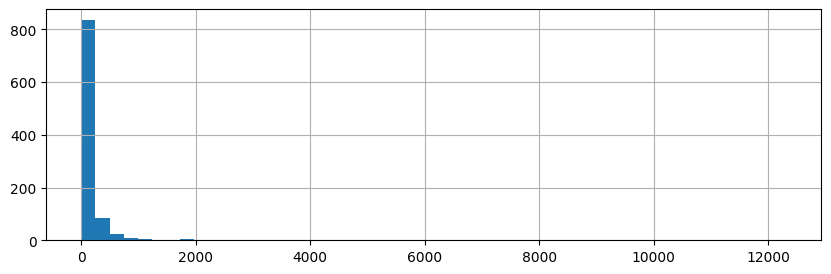

In [7]:
# Visualisaiton de la distribution des valeurs de la variable cible
plt.figure(figsize=(10,3))
Data_ml[Variable_cible].hist(bins=50)

In [8]:
# Visualisation des 10 plus fortes valeurs de la variable cible
Data_ml.sort_values(Variable_cible, ascending=False).head(10)

,PrimaryPropertyType,Neighborhood,NumberofFloors,PropertyGFAParking,ENERGYSTARScore,TotalGHGEmissions,StreetType,Electricity_prop,SteamUse_prop,GFAbyfloor,MoreThanOneBuilding,AgeBuilding,nUseType
404,Hospital,East,14,0,54.0,12307.16,other,0.477874,0.462746,126140.714286,True,22,2
78,Hospital,East,8,0,29.0,10734.57,Avenue,0.575534,0.418215,144836.375000,True,16,2
63,Hospital,Northeast,10,0,10.0,8145.52,Way,0.455581,0.000000,87900.000000,True,63,1
962,Hospital,East,8,0,74.0,6330.91,Street,0.549330,0.450670,46808.250000,False,96,1
76,Hospital,Central,5,0,34.0,4906.33,Avenue,0.409662,0.000000,119503.800000,True,26,2
665,Hospital,Northwest,1,0,85.0,3278.11,other,0.433143,0.000000,415632.000000,True,50,2
667,Medical Office,East,3,0,60.0,3238.24,Avenue,0.467523,0.000000,197327.000000,False,52,4
146,Logement,Downtown,12,0,45.0,2573.75,Street,0.426273,0.503475,45192.083333,False,93,2
27,Logement,Downtown,34,146694,63.0,2451.58,Avenue,0.565999,0.144138,24927.000000,False,34,3
2,Logement,Downtown,41,196718,43.0,2089.28,Avenue,0.682307,0.297113,18521.756098,False,47,1


**Stratégies de découpage précédemment testées**

In [9]:
#Data_ml['Target_cat'] =(Data_ml[Variable_cible]>2000).astype('int')
#Data_ml =  is_outliers_iqr(Data_ml, Variable_cible)
#Data_ml = Data_ml[Data_ml[Variable_cible]< 2000]

**Stratégie de découpage conservée pour cette variable**

In [10]:
# Construction d'une variable catétorielle pour classer les propriétés par quantile 
Data_ml['Target_cat'] =  pd.qcut(Data_ml[Variable_cible], 5, labels=[f'Category_{i+1}' for i in range(5)])

# Définition d'un random state
rdm_stt = 0

# Séparation du jeu de données 
trainset, testset = train_test_split(Data_ml, test_size=0.2, random_state=rdm_stt, stratify=Data_ml['Target_cat'])

# Stockage du nom de la stratégie
Strategy = '2_cat_quantile5'

# Définition de la variable de stratification qui sera utilisée en validation croisée
Stratified_feature = trainset['Target_cat']

# Stockage du nom de la stratégie
Strategy = '2_cat_quantile5'

# Visualisation des valeurs de quantiles utilisées
Data_ml[Variable_cible].quantile([0.2,0.4,0.6,0.8])

0.2     15.290
0.4     35.778
0.6     72.292
0.8    179.676
Name: TotalGHGEmissions, dtype: float64

# Feature engineering

Lors de la phase création de nouvelles features, nous avons créée des variables représentant la proportion d'éléctricité utilisée, de vapeur d'eau utilisée et d'éléctricité utilisée. Ces données calculées à partir du relevé ne seront peut être pas disponibles pour les nouveaux bâtiments. Nous allons donc les utiliser pour calculer des valeurs moyenne par catégorie de propriété sur le jeu de données d'entrainement qui seront ensuite imputée sur le jeu de données test avec une méthode fit et transform afin de pouvoir intégrer cette étape dans une pipeline.

In [11]:
class GroupMeanEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, var,  group1, group2=None,  new_col_names=None):
        
        # Initialisation du transformeur
        self.group1 = group1
        self.group2 = group2
        self.var = var
        self.new_col_names = new_col_names 

    def fit(self, X, y=None):
        
        # Calcul des moyennes par groupes d'une première variable catégorielle
        self.group1_means_ = {
            v: X.groupby(self.group1)[v].mean()
            for v in self.var
        }
        
        # Si deuxième variable renseignée -> Calcul des moyennes par groupes de cette variable
        if self.group2:
            self.group2_means_ = {
                v: X.groupby(self.group2)[v].mean()
                for v in self.var
            }
        else:
            self.group2_means_ = {}

        return self

    def transform(self, X):
        X = X.copy()
        for v, new_col in zip(self.var, self.new_col_names):
            # Extraction des moyennes pour le groupe 1
            group1_mean_series = self.group1_means_[v]
            X[new_col] = X[self.group1].map(group1_mean_series)
        
            # Remplissage du reste des observations si une deuxième variable a été renseignée
            if self.group2:
                group2_mean_series = self.group2_means_[v]
                group2_vals = X[self.group2].map(group2_mean_series)
                X[new_col] = X[new_col].fillna(group2_vals)
          
        return X
 
    def fit_transform(self, X, y=None):
        return self.fit(X, y).transform(X)


In [12]:
# Appel de la fonction et sauvegarde du transformeur personnalisé
group_encoder = GroupMeanEncoder(
    group1='PrimaryPropertyType',
    var = ['Electricity_prop', 'SteamUse_prop'],
    new_col_names=['Electricity_prop', 'SteamUse_prop']
)

# Fonctions d'évaluation de la performance du modèle

Les performances de chacun des modèles qui va être testé sera évaluée par validation croisée. Le jeu d'entrainement sera alors de nouveau subdivisé en k portions. A chaque itération, une portion serivra de jeu de validation, c'est à dire qu'elle ne sera pas vu par le modèle pendant l'entrainement, tandis que les k-1 portions restantes seront utilisées pour entrainer le modèle. Ce processus sera répété k fois, de manière à ce que chaque portion soit utilisée une fois comme jeu de validation. 

Afin d'évaluer la performance des différents modèles qui vont être testés, nous allons définir différentes fonctions.
- une fonction qui permettra de calculer les scores brutes et le score moyen obtenus après validation croisés, ainsi que les scores obtenus sur le jeu d'entrainement et sur le jeu de test. Cette fonction affichera également la distribution des scores obtenus après validation croisée
- une fonction permettant de visualiser les erreurs de prédiction par deux représentations graphiques
- une fonction montrant la capacité d'apprentissage des modèles en fonction de différents paramètre telles que la taille des jeux de données.

In [13]:
def evaluation_model(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest, n_split, scoring, scoring_name, strat_col=Stratified_feature,
                     feat_extr='passthrough', feature_eng = group_encoder, target_transformer=FunctionTransformer(), 
                    affichage=True):
    
    """
    Entraîne et évalue un modèle de machine learning à l'aide d'une pipeline complète
    incluant ingénierie de variables, prétraitement, sélection de features et
    transformation de la variable cible, avec validation croisée.

    La fonction réalise :
    - une validation croisée (KFold ou StratifiedKFold),
    - un entraînement final du modèle sur l'ensemble d'entraînement,
    - une évaluation sur les jeux d'entraînement, de validation et de test,
    - un affichage optionnel des résultats et de la distribution des scores.

    Paramètres:
     - Coltransf (sklearn.compose.ColumnTransformer): Transformer appliqué aux colonnes (encodage, scaling, etc.).
     - model (estimator sklearn): Modèle de prédiction (régression) compatible scikit-learn.
     - Xtrain (pandas.DataFrame or array-like): Données d'entraînement (features).
     - Ytrain (pandas.Series or array-like): Variable cible associée aux données d'entraînement.
     - Xtest (pandas.DataFrame or array-like): Données de test.
     - Ytest (pandas.Series or array-like): Variable cible associée aux données de test.
     - n_split (int): Nombre de folds pour la validation croisée.
     - scoring (callable): Fonction de scoring utilisée pour évaluer les performances 
     (ex. `mean_absolute_error`, `r2_score`, etc.).
     - scoring_name (str): Nom du score, utilisé pour l'affichage et le reporting.
     - strat_col (array-like or None, default=Stratified_feature): Variable utilisée pour la stratification lors de la validation croisée.
        Si None, une validation croisée classique (KFold) est utilisée.
     - feat_extr (estimator or 'passthrough', default='passthrough'): Étape de sélection ou d'extraction de features.
     - feature_eng (estimator, default=group_encoder): Transformer appliqué pour l'ingénierie de variables avant le prétraitement.
     - target_transformer (transformer, default=FunctionTransformer()) : Transformation appliquée à la variable cible via
     `TransformedTargetRegressor`.
     - affichage (bool, default=True): 
        Si True, affiche les scores détaillés et un boxplot des scores de validation.
        Si False, retourne uniquement les résultats sous forme structurée.

    Sortie
     - pandas.DataFrame or list of dict
        - Si `affichage=True` : DataFrame contenant les scores d'entraînement,
          de validation (moyenne et écart-type) et de test.
        - Si `affichage=False` : liste de dictionnaires avec les mêmes informations.
    """
    
    # Initialisation de la liste stockant les résultats
    res=[]
    

    # Choix du type de KFold
    if strat_col is not None:
        skf = StratifiedKFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(skf.split(Xtrain, strat_col))
        if affichage==True:
            print(f"✅ Stratification")
    else:
        kf = KFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(kf.split(Xtrain))
        if affichage==True:
            print("ℹ️ Aucune stratification demandée.")
            
    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor 
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)
       
         
    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model_t) 
    ])
    
    # Adaptation de la fonction de scoring
    scorer = make_scorer(scoring)
     
    # Cross-validation
    val_score = cross_val_score(pipeline, Xtrain, Ytrain, cv=cv, scoring=scorer, error_score='raise', n_jobs=-1)

    # Entraînement du modèle sur le jeu d'entrainement
    pipeline.fit(Xtrain, Ytrain)
    
    # Prédiction des résultats sur le jeu d'entrainement et de test
    test_predictions = pipeline.predict(Xtest)
    train_predictions = pipeline.predict(Xtrain)
    
    # Calcul des scores 
    test_score = scoring(Ytest, test_predictions)
    train_score = scoring(Ytrain, train_predictions)

    # Reformatage des scores
    train_score =(train_score).round(2)
    val_score = (val_score).round(2)
    val_score_mean = (val_score).mean().round(2)
    val_score_std  = val_score.std().round(2)
    test_score = (test_score).round(2)
    
    # Stockage des scores
    row = {
        "model": model.__class__.__name__, 
        "scoring": scoring_name,
        "train_score": train_score,
        "val_score mean": val_score.mean().round(2),
        "val_score std": val_score.std().round(2),
        "test_score": test_score
        }
    
    if affichage==True:
    # Afficher les résultats        
        print(scoring_name, "sur les validation sets:", val_score) 
        print(scoring_name, "moyen sur les validation sets:", val_score_mean)
        print(scoring_name, "ecart type sur les validation sets:", val_score_std)
        print(scoring_name, "sur le train set:", train_score)
        print(scoring_name, "sur le test set:", test_score)

        # Stockage des résultats dans une datadrame
        res = pd.DataFrame([row])
        
        # Nom du modèle
        model_name = model.__class__.__name__

        # Construction du graphique
        plt.figure(figsize=(12,2))
        sns.boxplot(x=val_score)
        plt.title(f'Disctribution des scores de {scoring_name} obtenus en validation croisée')
        plt.savefig(f'../Output/Modélisation/Score de validation croisée/Emissions/Distribution du score de {scoring_name} obtenu en validation croisée (émissions - {model_name}).png', format='png')

        
    else: 
        res.append(row)
    
    return res


In [14]:
def graph_erreur(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest,
                 feat_extr='passthrough', feature_eng = group_encoder, target_transformer=FunctionTransformer(),
                Xlim=None, Ylim=None, Savefig=True, Optimisation=""):
    
    """
    Entraîne un modèle de régression sur les données d'entraînement et génère deux graphiques pour évaluer les erreurs de prédiction sur un jeu de test.

    Paramètres
     - Coltransf (transformer ou pipeline): Transformateur ou pipeline appliqué aux variables explicatives dans le pipeline global.
     - model (estimator scikit-learn): Modèle de régression à entraîner.
     - Xtrain (DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (Series ou array-like): Cibles d'entraînement.
     - Xtest (DataFrame ou array-like): Données de test (features).
     - Ytest (Series ou array-like): Cibles de test.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.
     - target_transformer (transformer, optionnel (par défaut FunctionTransformer())): Transformateur appliqué à la variable cible via TransformedTargetRegressor.
     - Xlim (float ou None, optionnel (par défaut None)): Limite maximale de l'axe x du nuage de points (valeurs réelles). Si None, pas de limite fixée.
     - Ylim (float ou None, optionnel (par défaut None)): Limite maximale de l'axe y du nuage de points (valeurs prédites). Si None, pas de limite fixée.
     - Savefig (bool, par défaut True): Indique si la figure doit être sauvegardée
     - Optimisation (str, par défaut ""): Indique dans le nom de sauvegarde si le modèle a été optimmisé
    """

    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model_t) 
    ])
    
    # Entraînement du modèle sur le jeu d'entrainement
    pipeline.fit(Xtrain, Ytrain)

    # Prédiction des résultats sur le jeu de test
    test_predictions = pipeline.predict(Xtest)
    
    # Calcul des erreurs de prédiction
    err_hist = Ytest- test_predictions
    
    # Calcul de la moyenne des valeurs réelles
    mean_val = Ytest.mean()

    # Construction des graphiques
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    # Premier graphique (Histogramme avec les effectifs)
    counts, bins, patches = ax[0].hist(err_hist, bins=50)

    # Ajout des effectifs au-dessus de chaque barre
    for count, bin_left, bin_right in zip(counts, bins[:-1], bins[1:]):
        bin_center = (bin_left + bin_right) / 2
        ax[0].text(bin_center, count, str(int(count)), ha='center', va='bottom', fontsize=9)

    ax[0].set_xlabel("Erreur")
    ax[0].set_ylabel("Effectif")
    ax[0].set_title("Histogramme des erreurs")

    # Deuxième graphique (Nuage de points)
    ax[1].scatter(Ytest, test_predictions)
    ax[1].axvline(mean_val, color='blue', linestyle='--', label=f'Moyenne: {mean_val:.2f}')
    ax[1].set_xlabel("Valeur réelles")
    ax[1].set_ylabel("Valeur prédites")
    ax[1].set_title(f"{Variable_cible} prédites en fonction de {Variable_cible} réelles")
    
    # Adatation des limites du deuxième graphique si spécifiés en arguments
    if Xlim is not None : 
        ax[1].set_xlim(0, Xlim)
        
    if Xlim is not None : 
        ax[1].set_ylim(0, Ylim)
   
    # Ajout de la droite y = x
    x_values = ax[1].get_xlim()  
    ax[1].plot(x_values, x_values, 'r--', label="y = x")  

    # Ajout d'une légende
    ax[1].legend()

    # Ajustement des graphiques
    plt.tight_layout()
    
    # Sauvegarde des graphiques
    model_name = model.__class__.__name__ 
    if Optimisation == "":
        plt.savefig(f'../Output/Modélisation/Analyse des erreurs/Emissions/Représentation des erreurs de modélisation (émissions - {model_name}).png', format='png')
    else:
        plt.savefig(f'../Output/Modélisation/Analyse des erreurs/Emissions/Représentation des erreurs de modélisation (émissions - {model_name} - optimisé).png', format='png')

    # Affichage des graphiques
    plt.show()

In [15]:
def graph_erreur_var(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest, var, 
                 feat_extr='passthrough', feature_eng = group_encoder, target_transformer=FunctionTransformer()):
    
    """
    Entraîne un modèle de régression et affiche un nuage de points représentant les erreurs de prédiction en fonction d'une variable explicative spécifique.

    Paramètres
     - Coltransf (transformer ou pipeline): Transformateur ou pipeline appliqué aux variables explicatives dans le pipeline global.
     - model (estimator scikit-learn): Modèle de régression à entraîner.
     - Xtrain (DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (Series ou array-like): Cibles d'entraînement.
     - Xtest (DataFrame ou array-like): Données de test (features).
     - Ytest (Series ou array-like): Cibles de test.
     - var (str): Nom de la variable explicative selon laquelle représenter les erreurs.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.
     - target_transformer (transformer, optionnel (par défaut FunctionTransformer())): Transformateur appliqué à la variable cible via TransformedTargetRegressor.

    """
    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model_t) 
    ])
    
    # Entraînement du modèle sur le jeu d'entrainement
    pipeline.fit(Xtrain, Ytrain)

    # Prédicrion des résultats sur le jeu de test
    test_predictions = pipeline.predict(Xtest)

    # Calcul des erreurs de prédictions
    err_hist = Ytest- test_predictions

    # Construction du graphique
    plt.scatter(err_hist, Xtest[var])
    plt.title(f'Représentation des erreurs en fonction de la variable {var}')
    plt.tight_layout()
    plt.savefig(f'../Output/Modélisation/Analyse des erreurs/Emissions/Représentation des erreurs de modélisation en fonction de la variable {var} (émissions - {model_name} - optimisé).png', format='png')
    plt.show()

In [16]:
def learning_curve_plot(Coltransf, model, X, Y, n_split, strat_col=Stratified_feature,
                        feat_extr='passthrough', feature_eng=group_encoder):
    """
    Trace la courbe d'apprentissage d'un modèle de machine learning en utilisant une validation croisée stratifiée ou non.

    Paramètres
     - Coltransf (transformer ou pipeline): Transformateur ou pipeline appliqué aux variables explicatives dans le pipeline global.
     - model (estimator scikit-learn): Modèle à entraîner.
     - X (DataFrame ou array-like): Variables explicatives.
     - Y (Series ou array-like): Variable cible.
     - n_split (int): Nombre de plis pour la validation croisée.
     - strat_col (array-like ou None, optionnel (par défaut Stratified_feature)): Variable de stratification pour la validation croisée stratifiée. Si None, stratification désactivée.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.
    """
    
    # Choix du type de KFold
    if strat_col is not None:
        strat_labels = strat_col
        skf = StratifiedKFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(skf.split(X, strat_labels))
        print(f"✅ Stratification")
    else:
        kf = KFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(kf.split(X))
        print("ℹ️ Aucune stratification demandée.")
                 
    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransf', Coltransf), 
       ('feature_selection', feat_extr),
        ('model', model) 
    ])
    
    # kearning curve
    N, train_score, val_score = learning_curve(pipeline, X, Y, 
                                           train_sizes=np.linspace(0.7,1,10), cv=cv, random_state=rdm_stt)
    # Construction du graphique
    plt.plot(N, train_score.mean(axis=1), label='train')
    plt.plot(N, val_score.mean(axis=1), label='validation')
    plt.title("Courbe d'apprentissage")
    plt.xlabel('train_sizes')
    plt.legend()

# Préprocessing

Différentes séquences de préprocessing vont être testées au fur et a mesure. Une première séquence sera la normalisation des features numériques ainsi que l'encodage des variables catégorielles. Les séquences de préprocessing seront ajoutées une a une dans la sections ci dessous au fur et a mesure des différents tests qui seront effectués. 

A noter que certains préprocessing peuvent différer selon le modèle. Par exemple, le paramétrage de l'encodage de type OneHotEncoder sera différent selon si le modèle est à base de regression linéaire ou à de relations non linéaires. En effet, pour une regression linéaire il sera préférable de retirer une des variables créées pour éviter d'introduire de la multicolinéarité dans le modèle tandis que pour les modèles non linéaires cela ne sera pas nécéssaire, ces derniers étant moins sensibles. On distinguera donc les préprocessing appliqués à ces différents types de modèles. 

In [17]:
# Préprocessing pour les méthodes linéaires
######################################################################################################""""""

# Coltransf_1_linéaire
Coltransf_1_lin = ColumnTransformer(
    transformers=[
        ('num1', MinMaxScaler(), num_cols) ,
        ('num2', MinMaxScaler(), log_cols) ,
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols),       
    ])

# Coltransf_2_linéaire
Coltransf_2_lin = ColumnTransformer(
    transformers=[
       ('num1', Pipeline([
            ('log_transform', FunctionTransformer(func=np.log1p, inverse_func=np.expm1, validate=False)),
            ('scaler', RobustScaler())
        ]), log_cols),
        ('num2', RobustScaler(), num_cols),
        ('cat', TargetEncoder(random_state=rdm_stt), cat_cols),
    ])

# Préprocessing pour les méthodes non linéaires
######################################################################################################""""""

# Coltransf_1_non_linéaire
Coltransf_1_no_lin = ColumnTransformer(
    transformers=[
        ('num1', MinMaxScaler(), num_cols) ,
        ('num2', MinMaxScaler(), log_cols) ,
        ('cat', OneHotEncoder( handle_unknown='ignore'), cat_cols),       
    ])

# Coltransf_2_non_linéaire
Coltransf_2_no_lin = ColumnTransformer(
    transformers=[
       ('num1', Pipeline([
            ('log_transform', FunctionTransformer(func=np.log1p, inverse_func=np.expm1, validate=False)),
            ('scaler', RobustScaler())
        ]), log_cols),
        ('num2', RobustScaler(), num_cols),
        ('cat', TargetEncoder(random_state=rdm_stt), cat_cols),
    ])


# Premier modele : LinearRegression

Un premier modèle qui sera testé sera la régression linéaire. Les résultats vont être stockés dans un tableau de manière à pouvoir comparer les performances de chacun des modèles qui sera testés. 

## Entrainement et évaluation du modèle 

In [18]:
# Initiationlisation de la table résultats et du préprocessing
resultat_step_1_var = ['model', 'scoring', 'train_score', 'val_score', 'test_score']
resultat_step_1 = pd.DataFrame(columns=resultat_step_1_var)

In [19]:
# Définition du premier modèle
model = LinearRegression()
Coltransf= Coltransf_1_lin

✅ Stratification
R² sur les validation sets: [ 0.67 -0.13 -2.5   0.5   0.73]
R² moyen sur les validation sets: -0.15
R² ecart type sur les validation sets: 1.22
R² sur le train set: 0.59
R² sur le test set: 0.63


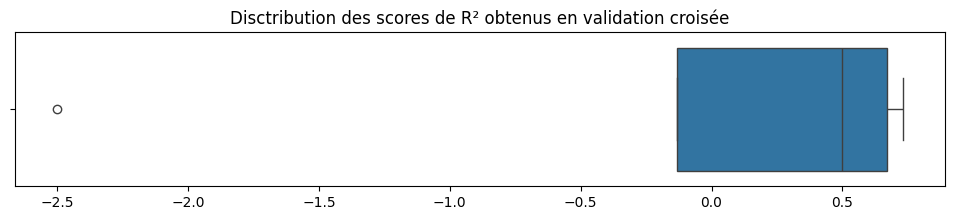

In [20]:
# Evaluation du R² du premier modèle
RES_1_a = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

- **val score** : les score obtenus sur la validation croisée sont très variables. On remarque qu'on a des folds où le modèle a bien su généraliser et d'autres pour lesquels le modèle a fait pire que la moyenne. Le modèle n'est pas stable selon les découpages. 
- **train score** : le score obtenu sur le jeu d'entrainement est correcte mais pas très élevé ce qui indique que le modèle n'a pas peut être pas suffisament réussi a tirer des relations entre les variables prédictives et la variable cible. Il y a un grand écart entre le score moyen obtenu après validation et le score obtenu sur le jeu d'entrainement ce qui pourrait suggérer de l'overfit. Cette observation est surtout causée par la variabilité des scores entres les différents folds. 
- **test score** : le score obtenu sur le jeu de test est plûtot statisfaisant.
 
 Ces résultats nous amène à plusieurs pistes d'améliorations
 - tester l'introduction d'une forme de régularisation pour réduire l'overfit
 - tester des méthodes d'ensemble comme le bagging pour réduire la variance 
 - tester d'autres méthodologies de préprocessing
 - tester un modèle non linéaire
 - tester une autre stratégie de découpage

Afin de pouvoir comparer les différents modèles on va s'intéresser à d'autres scores comme la MAE qui mesure l'erreur absolue moyenne et la RMSE qui mesure l'erreur quadratique moyenne. On peut également analyser plus finement les erreurs en visualisation un histogramme des erreurs ou alors en visualisant les valeurs prédites en fonction des valeurs réelles.

✅ Stratification
MAE sur les validation sets: [154.97 175.98 188.77 175.92 134.5 ]
MAE moyen sur les validation sets: 166.03
MAE ecart type sur les validation sets: 19.13
MAE sur le train set: 143.6
MAE sur le test set: 159.79


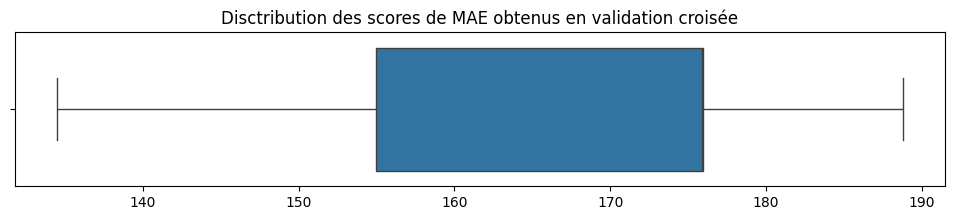

In [21]:
# Evaluation de la MAE du premier modèle
RES_1_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
RMSE sur les validation sets: [388.88 411.72 568.02 649.77 225.05]
RMSE moyen sur les validation sets: 448.69
RMSE ecart type sur les validation sets: 148.08
RMSE sur le train set: 375.01
RMSE sur le test set: 604.26


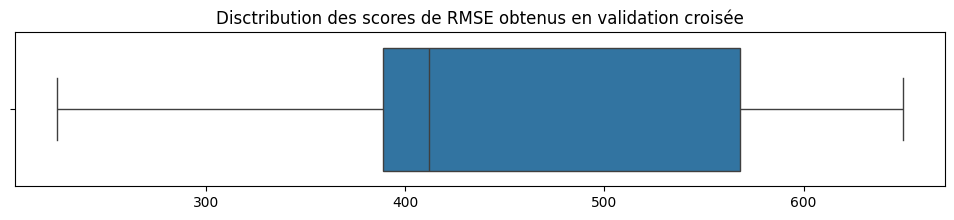

In [22]:
# Evaluation de la RMSE du premier modèle
RES_1_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

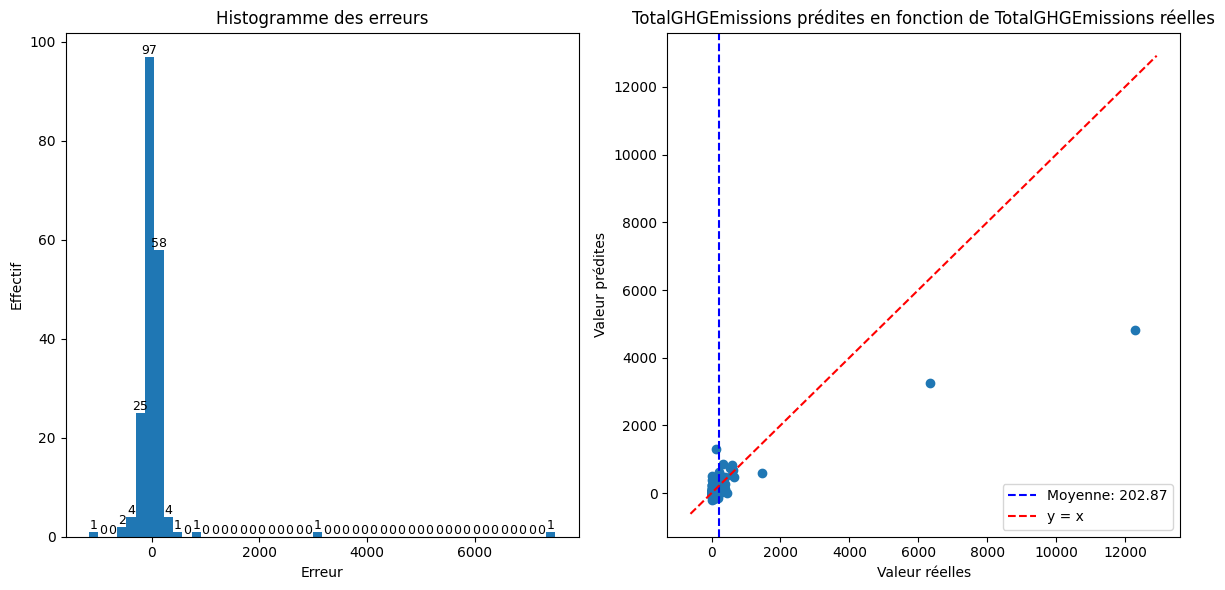

In [23]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

Les erreurs représentées dans l'histogramme correspondent à la différence entre la valeur réelle et la valeur prédite par le modèle. On remarque que
- pour la majorité des propriétés l'erreur est assez faible
- les erreurs les plus fortes semblent être obtenues pour pour les valeurs extrêmes. 
- les erreurs les plus fortes correspondent à des sous estimations par rapport aux valeurs réelles

✅ Stratification


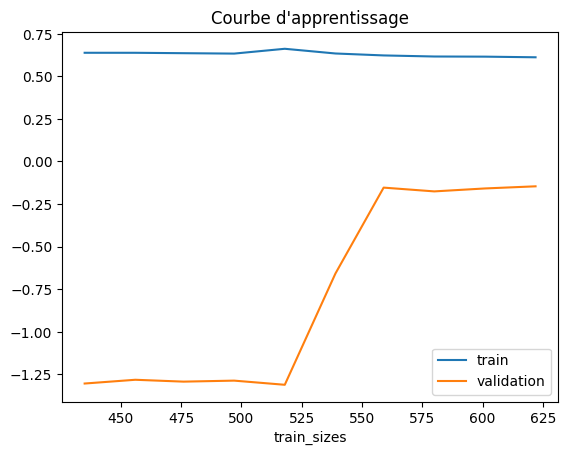

In [24]:
# Visulisation de la courbe d'apprentissage
learning_curve_plot(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 5)

Quand on augmente la taille du jeu d'entrainement, on observe une amélioration des scores de validation, mais ceux ci atteingent un plateau ne dépassant pas 0. Ainsi jouer sur les taille de jeu d'entrainement et de validation ne permettra pas d'atteindre des scores satisfaisant avec ce modèle.

In [25]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([RES_1_a, RES_1_b, RES_1_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.59,-0.15,1.22,0.63
0,LinearRegression,MAE,143.60,166.03,19.13,159.79
0,LinearRegression,RMSE,375.01,448.69,148.08,604.26


## Régularisation avec ElasticNet 

Pour compenser un overfit d'un modèle linéaire on peut utiliser des techniques de régularisation telle que Ridge qui va pénaliser certains coéfficients de la regression linéaire en réduisant leur ampleur ou telle que Lasso qui va ajouter une pénalité qui elle va forcer certains coéfficients à 0 entrainant ainsi une séléction de variables. Le modèle ElasticNet est un modèle prenant en compte les deux pénalités. Ce modèle permet d'équilibrer les avantages des deux modèles Ridge et Lasso. Les paramètres à considérer sont:
- le coéfficient de régularisation globale alpha qui contrôle à quel point on pénalise les grands coéfficients du modèle. Quand il est égal a 0, cela signigie qu'uil n'y a pas de régularisation. 
- le l1 ratio correspondant au ratio entre la pénalité de Ridge et la pénalité ajouté par Lasso. Quand il est égal a 0 cela implique que seul la pénalité Ridge est appliquée.
- le nombre d'itération maximum de l'algorithme d'optimisation avant qu'il ne s'arrête.

In [26]:
# Définition du deuxième modèle et du préprocessing
Coltransf= Coltransf_1_lin
model = ElasticNet(
    alpha=0.1,       
    l1_ratio=0.5,    
    max_iter=10000,
    random_state=rdm_stt
)

✅ Stratification
R² sur les validation sets: [0.25 0.27 0.49 0.16 0.43]
R² moyen sur les validation sets: 0.32
R² ecart type sur les validation sets: 0.12
R² sur le train set: 0.3
R² sur le test set: 0.22


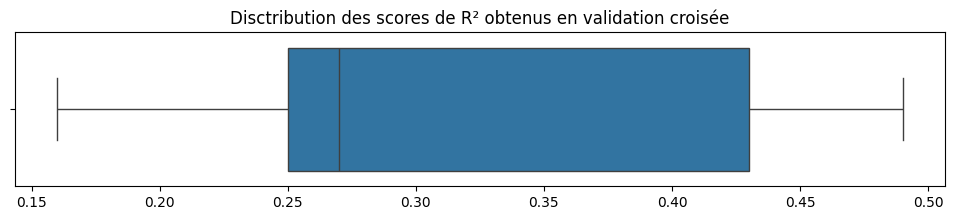

In [27]:
# Evaluation du R² du deuxième modèle
RES_2_a = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
MAE sur les validation sets: [172.67 158.5  126.6  203.44 143.48]
MAE moyen sur les validation sets: 160.94
MAE ecart type sur les validation sets: 26.21
MAE sur le train set: 155.27
MAE sur le test set: 186.33


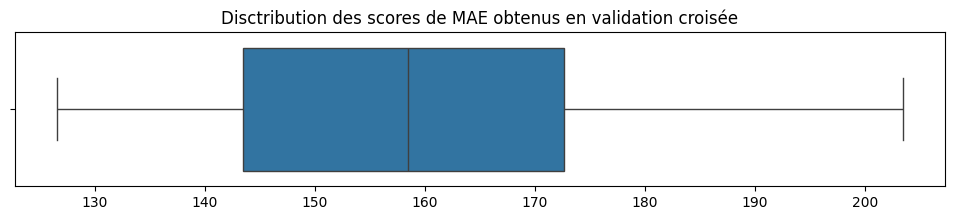

In [28]:
# Evaluation de la MAE du deuxième modèle
RES_2_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
RMSE sur les validation sets: [581.97 331.49 217.17 839.69 326.74]
RMSE moyen sur les validation sets: 459.41
RMSE ecart type sur les validation sets: 224.62
RMSE sur le train set: 491.64
RMSE sur le test set: 873.38


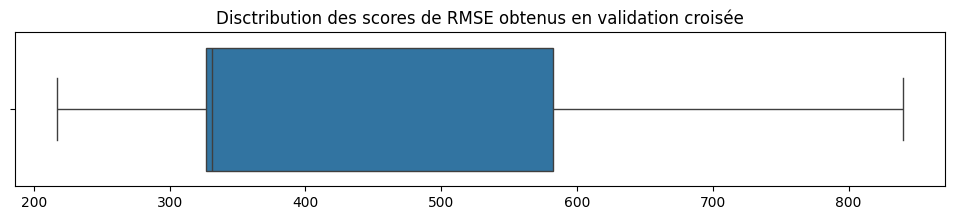

In [29]:
# Evaluation de la RMSE du troisième modèle
RES_2_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

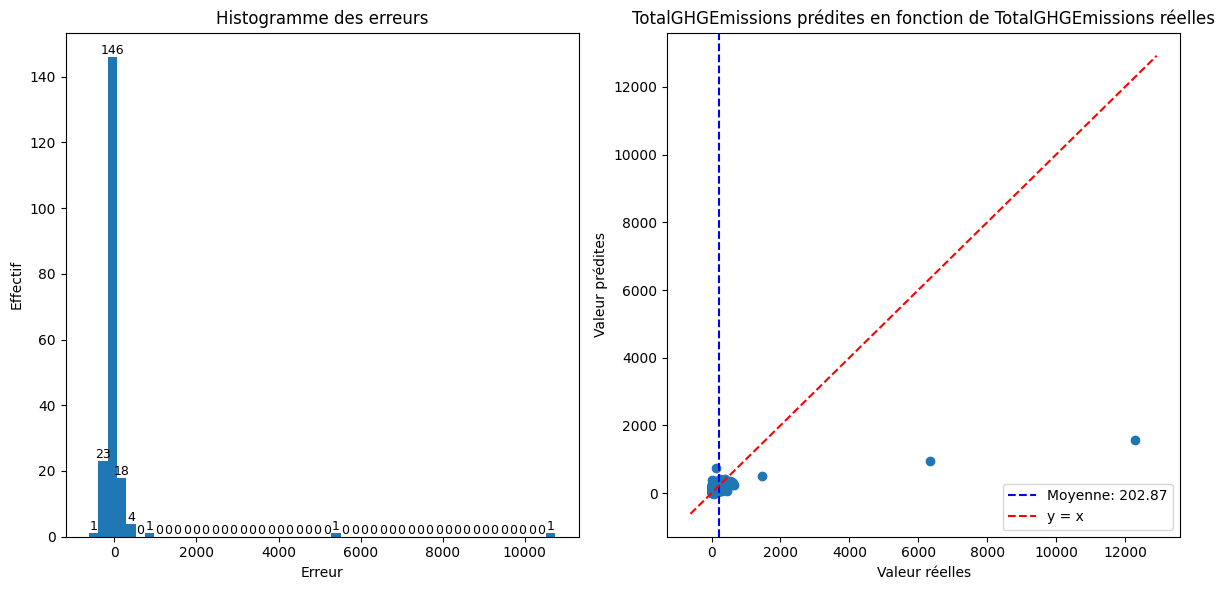

In [30]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [31]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_2_a, RES_2_b, RES_2_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.59,-0.15,1.22,0.63
0,LinearRegression,MAE,143.60,166.03,19.13,159.79
0,LinearRegression,RMSE,375.01,448.69,148.08,604.26
0,ElasticNet,R²,0.30,0.32,0.12,0.22
0,ElasticNet,MAE,155.27,160.94,26.21,186.33
0,ElasticNet,RMSE,491.64,459.41,224.62,873.38


Le modèle ElasticNet a permis d'améliorer les problèmes d'instabilité du R² après validation croisée. Il y a une meilleure cohérence entre les résultats obtenus en entrainement, après validation croisée puis en test mais on a là un modèle qui sous performe probablement à cause d'un mauvais paramétrage de la régularisation. Le modèle ElasticNet a fait moins d'erreurs absolues moyenne en validation croisée que la régression linéaire mais il a fait de plus grosse erreurs. Les paramètres de ce modèle pourraient être optimisés dans une étape ultérieure. 

## Bagging

Le Bagging est une méthode d'ensemble qui consiste à entrainer plusieurs modèles en parrallèles chacun sur un échantillon différent des données d'entraînement, obtenu par bootstrap (échantillonnage aléatoire avec remise). Dans le cas d’un problème de régression, la prédiction finale est obtenue en faisant la moyenne des prédictions de tous les modèles. Pour ce type de modèle on peut configurer
- le nombre de modèles à entrainer en parallèles, 
- le nombre ou la proportion d'observations à utiliser pour chaque arbre
- le nombre ou la proportion de variables a considérer pour chaque arbre
- la méthode bootstrap

In [32]:
# Définition du troisème modèle et du préprocessing
Coltransf= Coltransf_1_lin
model = BaggingRegressor(
    estimator=LinearRegression(),
    n_estimators=100,          
    max_samples=0.8,          
    max_features=1.0,        
    bootstrap=True,           
    random_state=rdm_stt)

✅ Stratification
R² sur les validation sets: [ 0.65 -0.08 -2.79  0.5   0.74]
R² moyen sur les validation sets: -0.2
R² ecart type sur les validation sets: 1.33
R² sur le train set: 0.59
R² sur le test set: 0.66


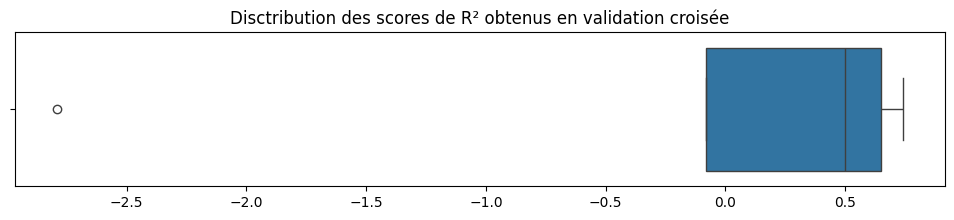

In [33]:
# Evaluation du R² du troisième modèle
RES_3_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
MAE sur les validation sets: [143.3  164.24 186.86 169.06 126.12]
MAE moyen sur les validation sets: 157.92
MAE ecart type sur les validation sets: 21.1
MAE sur le train set: 144.81
MAE sur le test set: 157.96


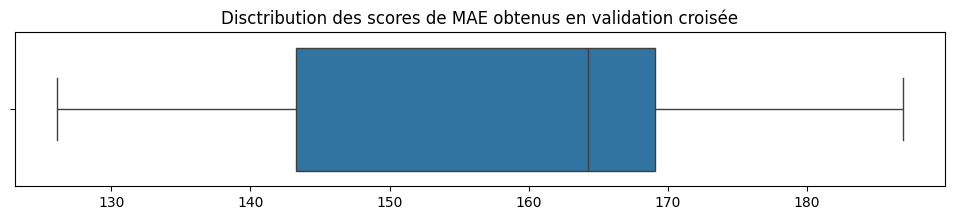

In [34]:
# Evaluation de la MAE du troisième modèle
RES_3_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
RMSE sur les validation sets: [396.2  403.3  591.43 648.37 221.23]
RMSE moyen sur les validation sets: 452.11
RMSE ecart type sur les validation sets: 152.8
RMSE sur le train set: 377.25
RMSE sur le test set: 576.27


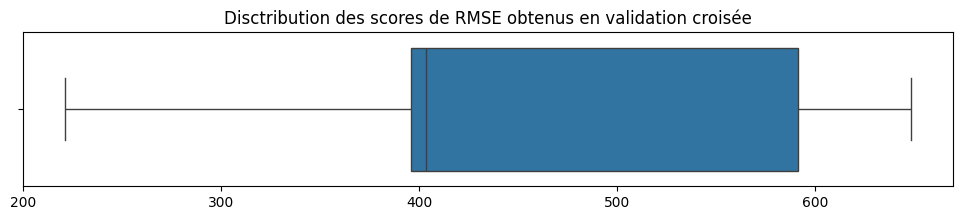

In [35]:
# Evaluation de la RMSE du troisième modèle
RES_3_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

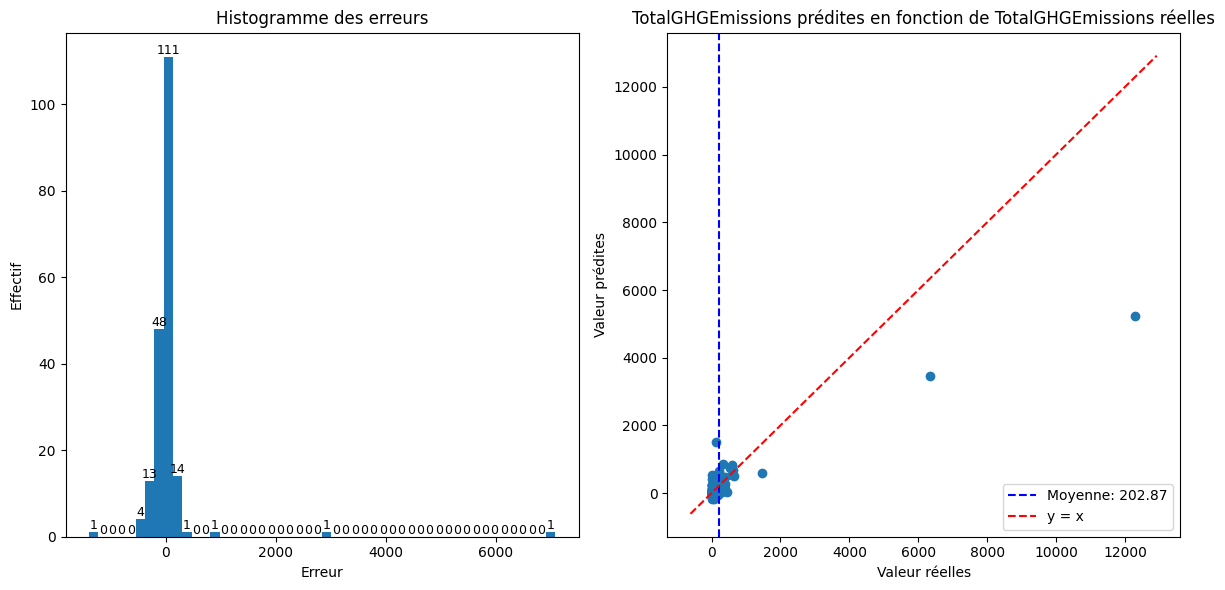

In [36]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [37]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_3_a, RES_3_b, RES_3_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.59,-0.15,1.22,0.63
0,LinearRegression,MAE,143.60,166.03,19.13,159.79
0,LinearRegression,RMSE,375.01,448.69,148.08,604.26
0,ElasticNet,R²,0.30,0.32,0.12,0.22
0,ElasticNet,MAE,155.27,160.94,26.21,186.33
0,ElasticNet,RMSE,491.64,459.41,224.62,873.38
0,BaggingRegressor,R²,0.59,-0.20,1.33,0.66
0,BaggingRegressor,MAE,144.81,157.92,21.10,157.96
0,BaggingRegressor,RMSE,377.25,452.11,152.80,576.27


Les différents scores et leur distributions après validation croisés sont similaires à ceux obtenus avec la régression linéaire simple. Le bagging n'a pas amélioré les problèmes de variances qui sont toujours présents. Les mauvaises performances moyennes sont de nouveau dû à certains folds où le modèle fait des prédictions moins bonnes que ne le ferait la moyenne. Ici, les paramètres n'ont pas été optimisés. Une optimisation des paramètres de ce modèle pourrait permettre d'améliorer un peu plus les performances du modèle. Cela sera pourra être fait dans une étape ultérieure.

# Autres modèles 

## Abres de décision 

Les arbres de décisions correspondent à des modèles non linéaires. Ils vont établir leur prédiction en différentes étapes correspondant à une série de décisions binaires. A chacune des étapes qu'on appelle noeud, le modèle va considérer une variable et une valeur seuil pour diviser le jeu de données en deux sous groupes, le but étant à chaque étape de minimiser l'erreur de prédiction. A la suite des différentes étapes, la prédiction correspond à la moyenne des valeurs de la variable à prédire dans chacun des sous groupes obtenus. Les sous-groupes obtenus à la dernière étape correspondent aux feuilles de l'arbre. Pour ce modèle, les principaux paramètres à configurer sont:
- La profondeur de l'arbre (nombre d'étape où des décisions seront prises par le modèle)
- Le nombre ou la prorportion d'observations requis pour diviser un noeud
- Le nombre ou la proportion d'observations minimum dans une feuille
- Le nombre maximum de features testés à chaque étape de division

In [38]:
# Définition du quatrième modèle
model = DecisionTreeRegressor(max_depth=3, 
                              min_samples_leaf=5,
                              max_features='sqrt', 
                              min_samples_split=20,
                             random_state=rdm_stt)
Coltransf= Coltransf_1_no_lin

✅ Stratification
R² sur les validation sets: [ 0.38 -0.41 -3.15  0.28  0.37]
R² moyen sur les validation sets: -0.51
R² ecart type sur les validation sets: 1.35
R² sur le train set: 0.3
R² sur le test set: 0.28


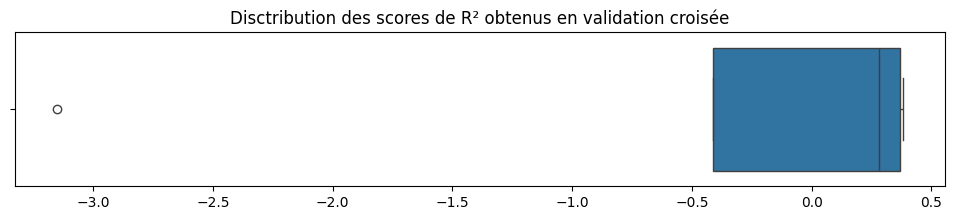

In [39]:
# Evaluation du R² du quatrième modèle et du préprocessing
RES_4_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
MAE sur les validation sets: [177.37 191.8  189.76 205.7  158.84]
MAE moyen sur les validation sets: 184.69
MAE ecart type sur les validation sets: 15.74
MAE sur le train set: 171.12
MAE sur le test set: 196.8


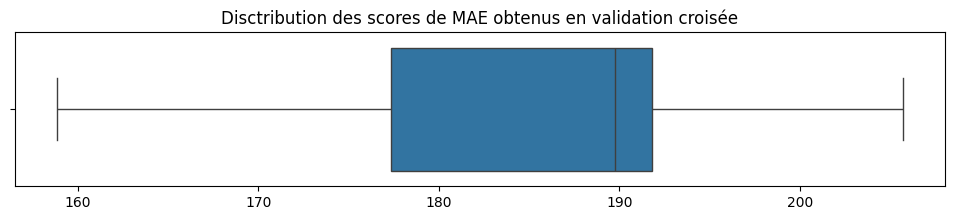

In [40]:
# Evaluation de la MAE du quatrième modèle
RES_4_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
RMSE sur les validation sets: [527.75 460.05 618.44 778.47 342.45]
RMSE moyen sur les validation sets: 545.43
RMSE ecart type sur les validation sets: 147.27
RMSE sur le train set: 490.25
RMSE sur le test set: 839.79


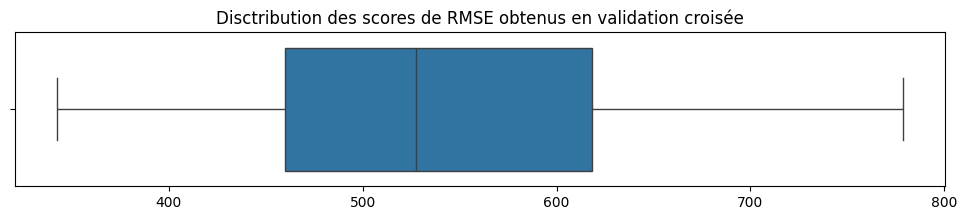

In [41]:
# Evaluation de la RMSE du quatrième modèle
RES_4_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

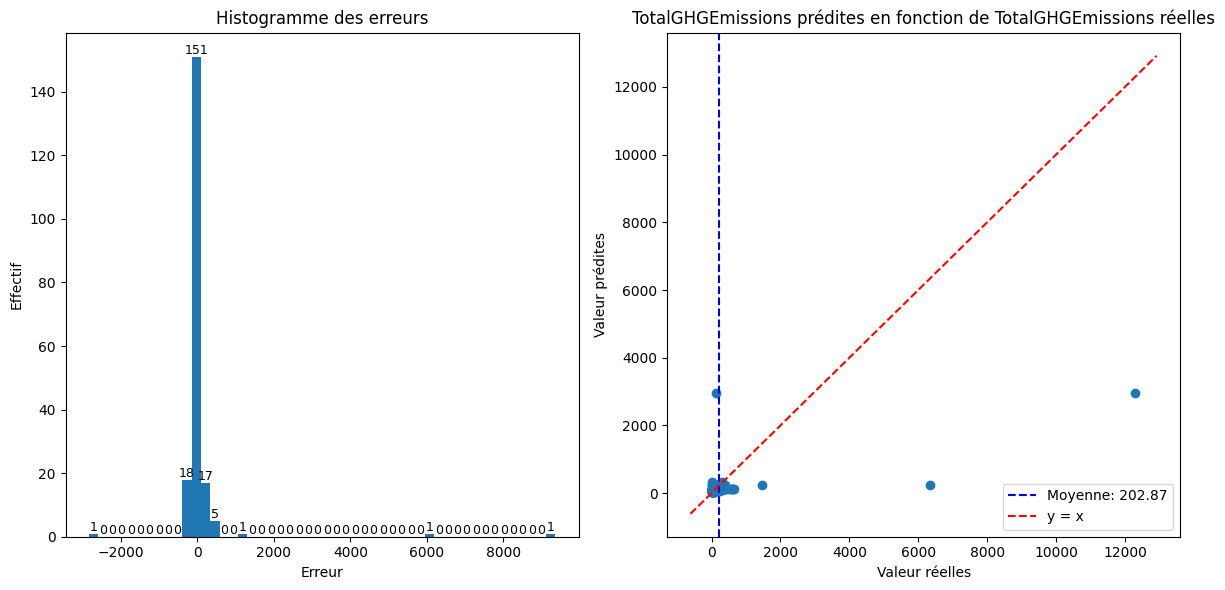

In [42]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [43]:
# Concaténation et visualisation de la table de résultats 
resultat_step_1 = pd.concat([resultat_step_1, RES_4_a, RES_4_b, RES_4_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.59,-0.15,1.22,0.63
0,LinearRegression,MAE,143.60,166.03,19.13,159.79
0,LinearRegression,RMSE,375.01,448.69,148.08,604.26
0,ElasticNet,R²,0.30,0.32,0.12,0.22
0,ElasticNet,MAE,155.27,160.94,26.21,186.33
0,ElasticNet,RMSE,491.64,459.41,224.62,873.38
0,BaggingRegressor,R²,0.59,-0.20,1.33,0.66
0,BaggingRegressor,MAE,144.81,157.92,21.10,157.96
0,BaggingRegressor,RMSE,377.25,452.11,152.80,576.27
0,DecisionTreeRegressor,R²,0.30,-0.51,1.35,0.28


On observe ici des scores très mauvais et une forte variance des résultats après validation croisée. Il s'agit des pires scores obtenus comparativement aux autres modèles. Le score obtenus sur les données d'entrainement sont également mauvais ce qui indique un biais dans le modèle. A nouveau on observe une forte variance des scores après validation croisée. Pour réduire le biais on peut envisager d'appliquer une méthode de boosting. On peut également regarder ce que donnerait une méthode de bagging sur ce modèle.

## RandomForest

Les arbres de décisions ont une méthode de bagging qui leur est spécifique et qu'on appelle RandomForest. Le principe est le même que celui détaillé pour le bagging regressor. Plusieurs arbres sont entrainés en parallèles et la prédiciton finale correspondra à la moyenne des prédictions obtenues pour chaque arbre. 

In [44]:
# Définition du cinquième modèle et du préprocessing
Coltransf= Coltransf_1_no_lin
model = RandomForestRegressor(
    n_estimators=100,        
    max_depth=3,             
    min_samples_leaf=5,      
    max_features='sqrt',     
    random_state=rdm_stt)

✅ Stratification
R² sur les validation sets: [0.27 0.33 0.6  0.21 0.46]
R² moyen sur les validation sets: 0.37
R² ecart type sur les validation sets: 0.14
R² sur le train set: 0.47
R² sur le test set: 0.34


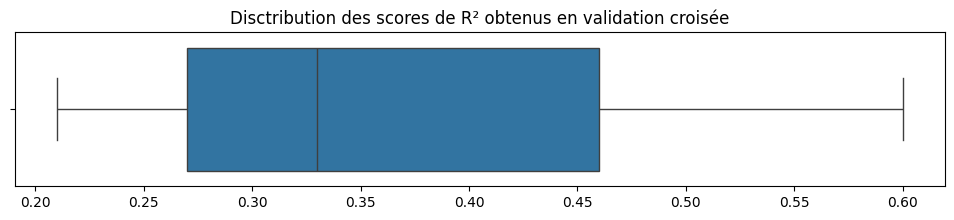

In [45]:
# Evaluation du R² du cinquième modèle
RES_5_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
MAE sur les validation sets: [156.77 145.42 114.52 189.66 136.56]
MAE moyen sur les validation sets: 148.59
MAE ecart type sur les validation sets: 24.78
MAE sur le train set: 141.43
MAE sur le test set: 173.25


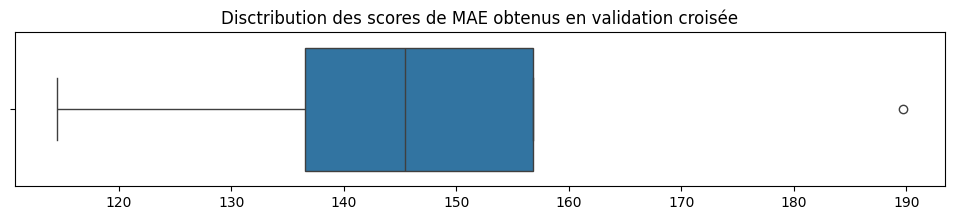

In [46]:
# Evaluation de la MAE du cinquième modèle
RES_5_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
RMSE sur les validation sets: [572.7  317.59 191.83 813.52 318.73]
RMSE moyen sur les validation sets: 442.87
RMSE ecart type sur les validation sets: 222.87
RMSE sur le train set: 429.1
RMSE sur le test set: 801.66


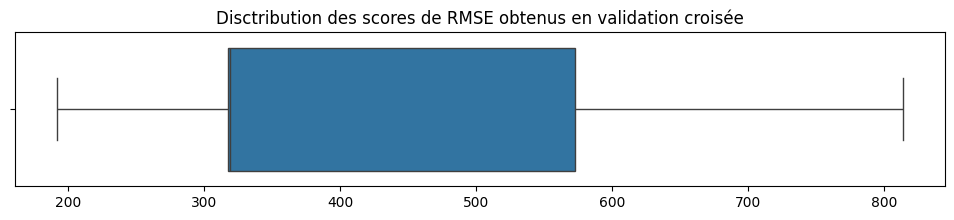

In [47]:
# Evaluation de la RMSE du cinquième modèle
RES_5_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

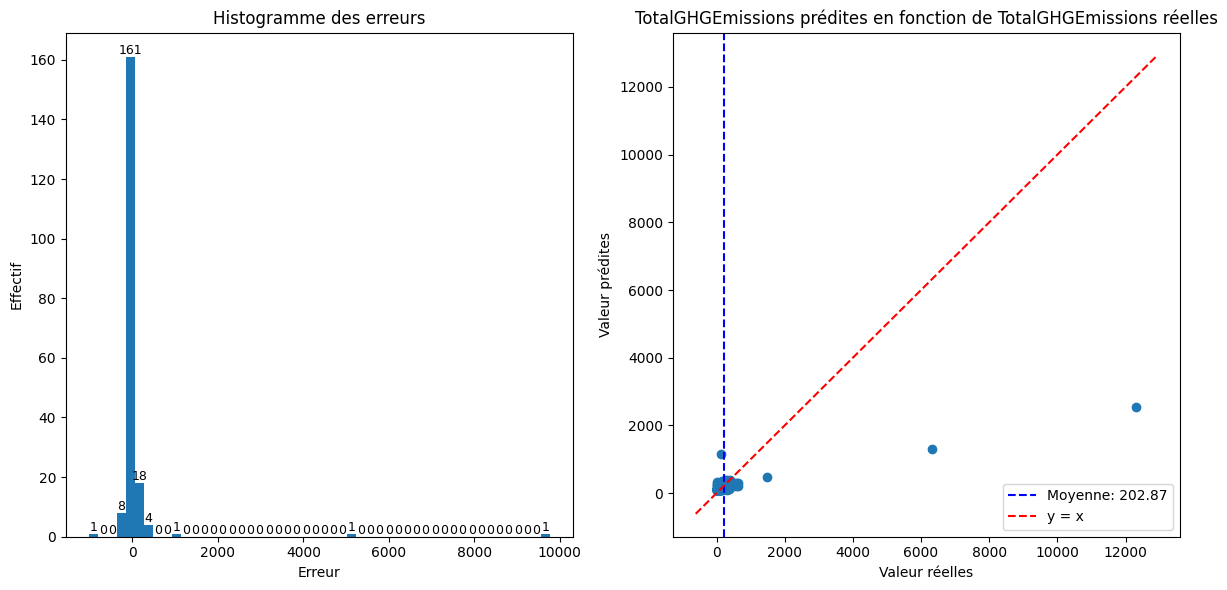

In [48]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [49]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_5_a, RES_5_b, RES_5_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.59,-0.15,1.22,0.63
0,LinearRegression,MAE,143.60,166.03,19.13,159.79
0,LinearRegression,RMSE,375.01,448.69,148.08,604.26
0,ElasticNet,R²,0.30,0.32,0.12,0.22
0,ElasticNet,MAE,155.27,160.94,26.21,186.33
0,ElasticNet,RMSE,491.64,459.41,224.62,873.38
0,BaggingRegressor,R²,0.59,-0.20,1.33,0.66
0,BaggingRegressor,MAE,144.81,157.92,21.10,157.96
0,BaggingRegressor,RMSE,377.25,452.11,152.80,576.27
0,DecisionTreeRegressor,R²,0.30,-0.51,1.35,0.28


Après l'utilisation d'une méthode de bagging avec RandomForest on observe une meilleure généralisation sur les données non vues comme l'indique les scores obtenus en validation croisée par rapport aux autres modèles (Regression linéaire, Regression linéaire avec bagging et arbre de décision). La variance est encore légèrement élevée en R² mais a été réduite de façon importante. La MAE ainsi que la RMSE  obtenues en validation croisées font partie des meilleures obtenues jusqu'à présent. Les scores obtenus en validation croisée bien que meilleurs restent encore assez faible. Là encore on peut jouer sur différents paramètres pour améliorer les performances de ce modèle. 

## XGboost

Le boosting consiste à construire des modèles de façon séquentielle où chaque modèle essaie de corriger les erreurs du précédent modèle en pondérant les prédictions des modèles successifs pour converger vers la meilleure prédiction globale. Il existe plusieurs algorithmes de boosting. XGBoost est basé sur la méthode de descente de gradient pour corriger les erreurs. Ici les principaux paramètres à configurer sont:
- le booster :
- le nombre de modèle à entrainer séquentiellement
- le taux d'apprentissage
- la profondeur de l'abre lorsque booster est fixé a gbtree
- le nombre de poids minimum d'observation dans une feuille (-> le nombre minimum d'observation dans une feuille quand aucun poids n'est fixé)
- le nombre ou la proportion d'observations à inclure dans chaque modèle
- le nombre ou la proportion de feature à inclure dans chaque modèle
- le gain minimum requis pour faire un split


In [50]:
# Définition du premier modèle et du préprocessing
Coltransf= Coltransf_1_no_lin
model =xgb = XGBRegressor(
    booster='gbtree',
    n_estimators=100,         
    learning_rate=0.1,        
    max_depth=3,             
    subsample=0.8,            
    random_state=rdm_stt)

✅ Stratification
R² sur les validation sets: [ 0.81 -0.06  0.08  0.77  0.87]
R² moyen sur les validation sets: 0.49
R² ecart type sur les validation sets: 0.4
R² sur le train set: 0.98
R² sur le test set: 0.92


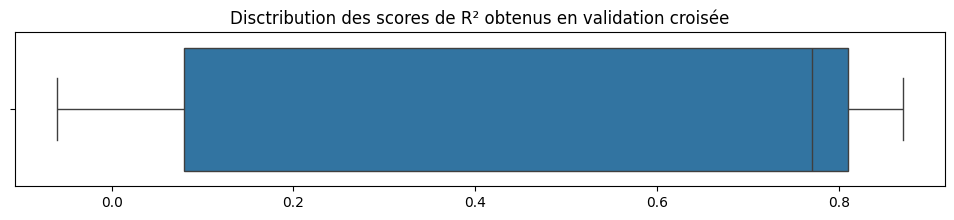

In [51]:
# Evaluation du R² du sixième modèle
RES_6_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
MAE sur les validation sets: [101.38 130.08 107.79 125.28  84.05]
MAE moyen sur les validation sets: 109.72
MAE ecart type sur les validation sets: 16.67
MAE sur le train set: 54.53
MAE sur le test set: 91.36


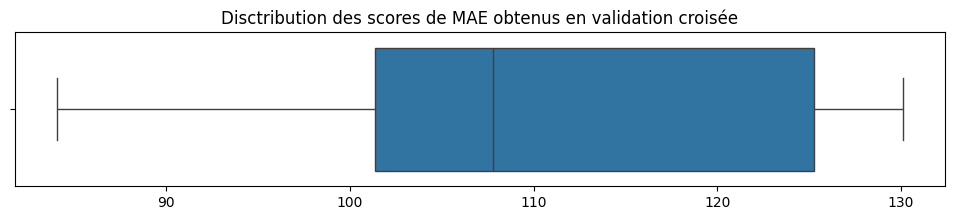

In [52]:
# Evaluation de la MAE du sixième modèle
RES_6_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
RMSE sur les validation sets: [294.64 399.26 291.73 443.53 156.04]
RMSE moyen sur les validation sets: 317.04
RMSE ecart type sur les validation sets: 99.82
RMSE sur le train set: 89.95
RMSE sur le test set: 272.59


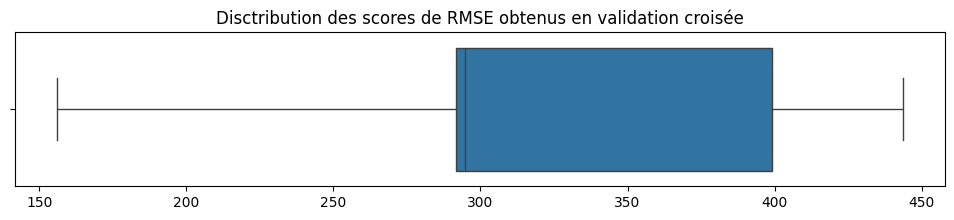

In [53]:
# Evaluation de la RMSE du sixième modèle
RES_6_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

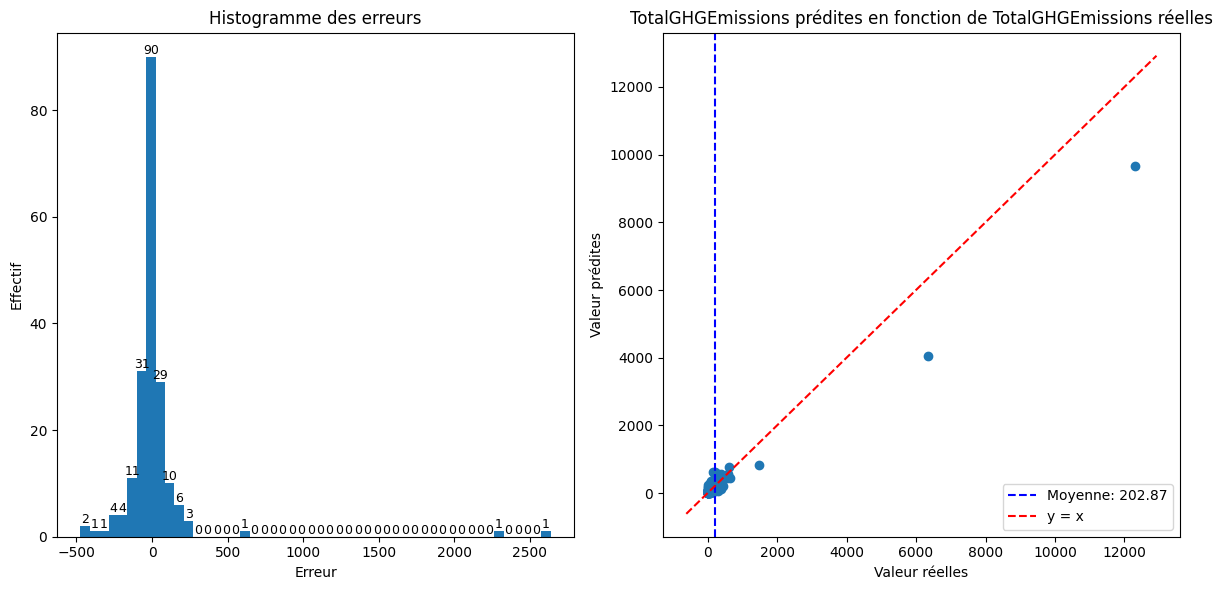

In [54]:
# Analyse des erreurs par représentation graphique
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [55]:
# Concaténation et visualisation de la table de résultats
resultat_step_1 = pd.concat([resultat_step_1, RES_6_a, RES_6_b, RES_6_c])
resultat_step_1

,model,scoring,train_score,val_score mean,val_score std,test_score
0,LinearRegression,R²,0.59,-0.15,1.22,0.63
0,LinearRegression,MAE,143.60,166.03,19.13,159.79
0,LinearRegression,RMSE,375.01,448.69,148.08,604.26
0,ElasticNet,R²,0.30,0.32,0.12,0.22
0,ElasticNet,MAE,155.27,160.94,26.21,186.33
0,ElasticNet,RMSE,491.64,459.41,224.62,873.38
0,BaggingRegressor,R²,0.59,-0.20,1.33,0.66
0,BaggingRegressor,MAE,144.81,157.92,21.10,157.96
0,BaggingRegressor,RMSE,377.25,452.11,152.80,576.27
0,DecisionTreeRegressor,R²,0.30,-0.51,1.35,0.28


Après l'utilisation d'une méthode de boosting avec XBGregressor Les performances obtenues sont encore meilleure que celles obtenues avec le RandomForest et le SVR. La variance est plus élevée pour le R² et est plus faible pour la RMSE et la MAE. On observe toutefois un overfit du modèle lorsqu'on compare les scores obtenus sur le jeu d'entrainement et les scores obtenus en validation croisée. De nouveau, on peut jouer sur différents paramètres pour améliorer les performances de ce modèle. 

# Modification du préprocessing

Lors de la phase d'exploration, il avait été observé que certaines variables, en particulier celles correspondant à des surfaces, avaient une distribution asymétrique avec une forte quantité de propriété avec des surface faibles, et peu de proriété dans les valeurs plus élevées. Il pourrait être inéterssant de transformer ces variables avec une fonction logarithmique pour obtenir une distribution plus normal.

Une autre modification du préprocessing concerne l'encodage des variables catégorielles qui peuvent etre encodées avec un encodeur de type OneHot comme jusqu'à maintenant mais également avec un encodeur de type Target, qui consiste à remplacer les valeurs de chaque catégorie par un estimateur calculé grâce à la target. 

Enfin, la méthode de normalisation des données peut également impacter la performance d'un modèle. Au lieu de faire une normalisation avec un Robust Scaler, on pourrait opter pour un MinMax scaler ou un Standard scaler.

Dans le test qui va suivre, la normalisation n'a pas été modifiée, mais une étape de transformation par une fonction logarithmique des variables liées à la surface et un encodage avec un encodeur de type Target ont été appliqués. 

In [56]:
# Définition du septième modèle et du préprocessing
Coltransf= Coltransf_2_no_lin
model = ElasticNet(
    alpha=0.1,       
    l1_ratio=0.5,    
    max_iter=10000,
    random_state=rdm_stt)

✅ Stratification
R² sur les validation sets: [ 0.54 -0.17 -0.43  0.4   0.56]
R² moyen sur les validation sets: 0.18
R² ecart type sur les validation sets: 0.4
R² sur le train set: 0.52
R² sur le test set: 0.48


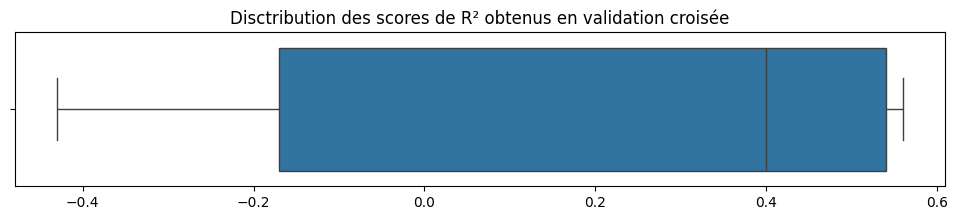

In [57]:
# Evaluation du R² du septième modèle
RES_7_a = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²')

✅ Stratification
MAE sur les validation sets: [180.84 197.44 229.62 193.32 182.04]
MAE moyen sur les validation sets: 196.65
MAE ecart type sur les validation sets: 17.68
MAE sur le train set: 172.42
MAE sur le test set: 211.53


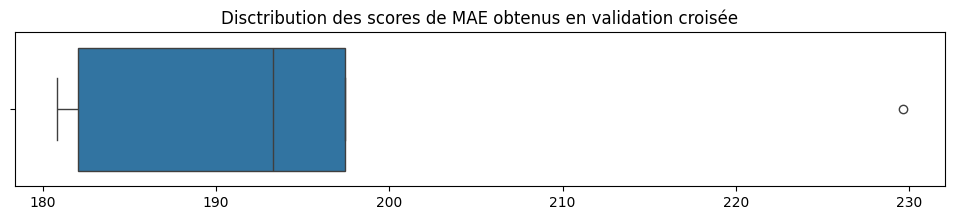

In [58]:
# Evaluation de la MAE du septième modèle
RES_7_b = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE')

✅ Stratification
RMSE sur les validation sets: [457.04 419.91 363.86 709.59 288.2 ]
RMSE moyen sur les validation sets: 447.72
RMSE ecart type sur les validation sets: 142.77
RMSE sur le train set: 407.04
RMSE sur le test set: 712.54


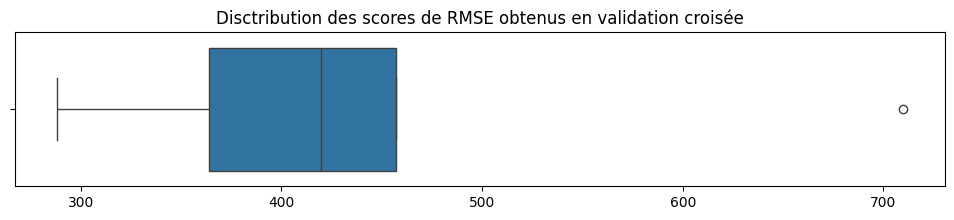

In [59]:
# Evaluation de la RMSE du septième modèle
RES_7_c = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE')

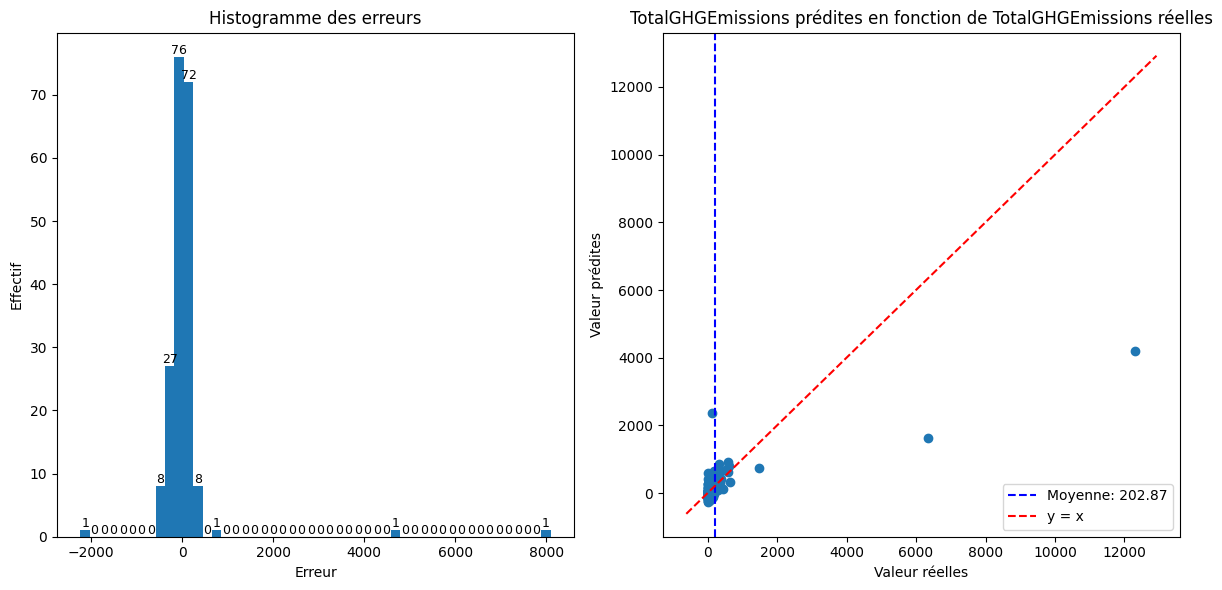

In [60]:
graph_erreur(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible])

In [61]:
# Concaténation et visualisation de la table de résultats
resultat_step_2 = pd.concat([RES_2_a, RES_2_b, RES_2_c, RES_7_a, RES_7_b, RES_7_c])
resultat_step_2

,model,scoring,train_score,val_score mean,val_score std,test_score
0,ElasticNet,R²,0.30,0.32,0.12,0.22
0,ElasticNet,MAE,155.27,160.94,26.21,186.33
0,ElasticNet,RMSE,491.64,459.41,224.62,873.38
0,ElasticNet,R²,0.52,0.18,0.40,0.48
0,ElasticNet,MAE,172.42,196.65,17.68,211.53
0,ElasticNet,RMSE,407.04,447.72,142.77,712.54


Dans le cas de l'ElasticNet, la modificiation du preprocessing entraine un meilleur apprentissage sur les données d'entrainement mais des scores de validations un peu plus bas avec une forte variabilité. Ici on a modifié deux étapes à la fois, et il serait intéressant de tester les différentes combinaisons possibles de preprocessing. Cela peut être fait dans une étape de gridSearch qui sera appliquée dans la section suivante. 

# Optimisations

Afin d'optimiser et d'évaluer les résulats de cette optimisation, une fonction va être utilisée de façon à garantir une méthodologie identique pour chaque modèle. Une représentation graphique sera également générée par une fonction de manière à pouvoir comparer plus facilement les résulats obtenus sur les différents modèles. 

Dans une première étape les modèles vont être optimisés sur un intervalle de valeur large pour pouvoir selectionner le ou les mmodèles les plus prometteurs qui seront optmisés de façon plus fine autour des meilleurs paramètres identifiés lors de la première phase.

## Fonction d'optimisation

In [62]:
def optimiser_models(models, Xtrain, Ytrain, Xtest, Ytest, n_split, scoring_list,
                     strat_col=Stratified_feature,  feat_extr='passthrough',
                     feature_eng=group_encoder):
    
    """
    Effectue une optimisation hyperparamétrique (GridSearchCV) pour plusieurs modèles en utilisant une validation croisée stratifiée ou non,
    et retourne un résumé des performances ainsi que les meilleurs estimateurs et résultats des recherches.

    Paramètres
     - models (dict): Dictionnaire contenant les modèles à optimiser et leurs grilles de paramètres associées.
     Chaque entrée doit être sous la forme : {'nom_du_modele': (estimator, param_grid)},
     où param_grid inclut notamment une clé 'Coltransfs_named' (mapping noms -> transformateurs) et 'Coltransfs' (liste des transformateurs).
     - Xtrain (DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (Series ou array-like): Cibles d'entraînement.
     - Xtest (DataFrame ou array-like): Données de test (features).
     - Ytest (Series ou array-like): Cibles de test.
    - n_split (int): Nombre de plis pour la validation croisée.
     - scoring_list (list de fonctions): Liste des fonctions de scoring à appliquer (ex: [r2_score, mean_absolute_error]).
     - strat_col (array-like ou None, optionnel (par défaut Stratified_feature)): Variable de stratification pour la validation croisée stratifiée. Si None, stratification désactivée.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut 'passthrough')): Transformateur pour la sélection/extraction de caractéristiques dans le pipeline.
     - feature_eng (transformer, optionnel (par défaut group_encoder)): Transformateur pour l'ingénierie des variables dans le pipeline.

    Sortie
     - resultats (pandas.DataFrame): DataFrame récapitulant les scores d'entraînement, validation (moyenne et écart-type) et test pour chaque modèle et métrique.
     - best_estimators (dict): Dictionnaire des meilleurs estimateurs obtenus pour chaque modèle après optimisation.
     - gs_results (dict): Dictionnaire des objets GridSearchCV complets pour chaque modèle (permettant un accès détaillé aux résultats).

    """
    
    # Initialisation des variables de sortie scotkant les résultats
    resultats = []
    best_estimators = {}
    gs_results = {}

    # Choix du type de KFold
    if strat_col is not None:
        strat_labels = strat_col
        skf = StratifiedKFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(skf.split(Xtrain, strat_labels))
        print(f"✅ Stratification")
    else:
        kf = KFold(n_splits=n_split, shuffle=True, random_state=rdm_stt)
        cv = list(kf.split(Xtrain))
        print("ℹ️ Aucune stratification demandée.")
        
    # Boucle sur les différents modèles    
    for model_name, (model, param_grid) in models.items():
        print(f"Optimisation du modèle : {model_name}")
                 
        # Extraction des noms associés aux différentes transformations
        coltransfs_named = param_grid['Coltransfs_named']
        reverse_named = {v: k for k, v in coltransfs_named.items()}
        
        # Définition d'une transformation par défaut pour initialiser la pipeline
        default_coltransf =  param_grid['Coltransfs'][0]
        
        # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
        model = TransformedTargetRegressor(regressor=model)
        
        # Pipeline
        pipeline = Pipeline([
            ('feature_engineering', feature_eng),
            ('Coltransfs', default_coltransf),
            ('feature_selection', feat_extr),
            ('model', model)
        ])

        # Construction d'une nouvelle grille de paramètre sans l'item correspondant aux noms
        param_grid_2 = param_grid.copy()
        param_grid_2.pop('Coltransfs_named', None)

         # Déinition d'un dictionnaire indiquant si le score doit être élevé (True) ou bas (False) lors de l'optimisation
        score_directions = {
            'r2_score': True,
            'mean_absolute_error': False,
            'root_mean_squared_error': False,
            }
        
        # Adapation de la fonction de scoring
        scoring_dict = {score.__name__: make_scorer(score, greater_is_better=score_directions.get(score.__name__, False)) for score in scoring_list}

        # Gridsearch
        gs = GridSearchCV(
            pipeline,
            param_grid=param_grid_2,
            scoring=scoring_dict,
            refit=scoring_list[0].__name__,
            cv=cv,
            n_jobs=-1)

        # Entrainement de la GridSearch
        gs.fit(Xtrain, Ytrain)
        
        # Stockage de la GridSearch
        gs_results[model_name] = gs
        
        # Stockage des meilleurs estimateurs obtenus après la GridSearch
        best_model = gs.best_estimator_
        best_estimators[model_name] = gs.best_estimator_
    
        # Extraction de la meilleure combinaison de transformation
        best_params = gs.best_params_
        best_coltransf_obj = best_params['Coltransfs']
        best_coltransf_name = reverse_named.get(best_coltransf_obj, str(best_coltransf_obj))

        # Extraction des meilleurs paramètres 
        model_params = {
            key.replace('model__', ''): val
            for key, val in best_params.items()
            if key.startswith('model__')}
        
        # Prédiction des valeurs du jeu de données test avec le meilleur modèle
        Ytrain_pred = best_model.predict(Xtrain)
        Ytest_pred = best_model.predict(Xtest)

        # Exctraction des différents scores associés au meilleur modèle
        for score_func in scoring_list:
            score_name = score_func.__name__
            
            # Calcul des scores
            score_train = score_func(Ytrain, Ytrain_pred)
            score_val_mean = gs.cv_results_[f'mean_test_{score_name}'][gs.best_index_]
            score_val_std = gs.cv_results_[f'std_test_{score_name}'][gs.best_index_]
            score_test = score_func(Ytest, Ytest_pred)

            # Formatage des scores
            score_train =(score_train).round(2)
            score_val_mean = (score_val_mean).round(2)
            score_val_std =(score_val_std).round(2)
            score_test = (score_test).round(2)
            
            if score_name !="r2_score":
                score_val_mean = - score_val_mean

            # Création d'une ligne avec tous les résultats
            row = {
                'model': model_name,
                'scoring': score_name,
                'train_score': score_train,
                'val_score mean': score_val_mean,
                'val_score std': score_val_std,
                'test_score': score_test,
                'best_coltransf': best_coltransf_name,
                'best_model_params': model_params
            }



            resultats.append(row)

    return pd.DataFrame(resultats), best_estimators, gs_results


In [63]:
def opt_graph(df_res, option=None):
    
    """
    Génère un graphique comparatif des performances de modèles à partir d'un DataFrame de résultats, 
    avec possibilité de grouper par une option spécifique (ex : hyperparamètre).

    Paramètres
     - df_res (pandas.DataFrame):  DataFrame contenant les résultats des modèles, avec au minimum les colonnes :
        - 'model' : nom du modèle
        - 'scoring' : nom de la métrique de performance (ex: r2_score, mean_absolute_error, etc.)
        - 'val_score mean' : moyenne du score en validation croisée
        - 'val_score std' : écart-type du score en validation croisée
        - 'train_score' : score sur l'ensemble d'entraînement
         - Optionnellement une colonne correspondant à `option` pour grouper les résultats.
     - option (str ou None, optionnel (par défaut None)): Nom d'une colonne de `df_res` selon laquelle grouper les résultats (ex : nom d'un hyperparamètre).
     Si None, le graphique compare uniquement les modèles.

    Sortie
     - plotnine.ggplot: Objet graphique plotnine représentant un barplot des scores de modèles, avec barres d'erreur sur la validation croisée.
     Les scores affichés sont la moyenne en validation croisée et le score sur le train set, séparés par facettes.
    """
    
    # Simplification des noms de scores
    anciennes_valeurs = ['r2_score', 'mean_absolute_error', 'root_mean_squared_error']
    nouvelles_valeurs = ['R²', 'MAE', 'RMSE']
    df_res['scoring'] = df_res['scoring'].replace(dict(zip(anciennes_valeurs, nouvelles_valeurs)))

    # Choix des variables d'identification
    id_vars = ['model', 'scoring']
    if option is not None:
        id_vars.append(option)

    # Reformatage de la dataframe
    resultats_pivot = pd.melt(
        df_res,
        id_vars=id_vars,
        value_vars=['val_score mean', 'train_score'],
        var_name='Score',
        value_name='Value'
    )

    # Extraction de la colonne de std
    std_pivot = df_res[['model', 'scoring', 'val_score std'] + ([option] if option else [])].copy()
    std_pivot = std_pivot.rename(columns={'val_score std': 'Std'})
    std_pivot['Score'] = 'val_score mean'


    # Jointure
    resultats_plot = resultats_pivot.merge(std_pivot, how='left', on=id_vars + ['Score']) 
    if option is not None:
        resultats_plot[option] = resultats_plot[option].astype(str)
        categories_ordonnees = sorted(resultats_plot['k'].unique(), key=lambda x: int(x))
        resultats_plot['k'] = pd.Categorical(resultats_plot['k'], categories=categories_ordonnees, ordered=True)
        resultats_plot = resultats_plot[resultats_plot['Score']=='val_score mean']

    # Dictionnaire de couleurs
    color_mapping = {
        'DummyRegressor': 'grey',
        'LinearRegression': 'bisque',
        'BaggingLinearRegression': 'wheat',
        'ElasticNet' : 'darkgoldenrod',
        'SVR': 'goldenrod',
        'RandomForest': 'lightgreen',
        'DecisionTree': 'darkgreen',
        'XGBregressor': 'green',
        'XGBRegressor': 'green'

    }
    # Définition de l'axe des x
    x_axis = option if option is not None else 'model'

    # Construction du graphique
    p = (ggplot(resultats_plot, aes(x=x_axis, y='Value', fill='model')) +
         geom_bar(stat='identity', position='dodge') +
         geom_errorbar(
             aes(ymin='Value - Std', ymax='Value + Std'),
             width=0.2,
             data=resultats_plot[resultats_plot['Score'] == 'val_score mean']
         ) +
         scale_fill_manual(values=color_mapping) +
         facet_grid('scoring ~ Score', scales='free_y') +
         theme(
             figure_size=(10, 7),
             axis_text_x=element_text(angle=45, ha='right', size=10),
             strip_text_x=element_text(size=10, weight='bold'),
             strip_text_y=element_text(size=10, weight='bold'),
             legend_position='none'
         ) +
         labs(x='Modèle' if option is None else option, y='Score')
    )
    
    # Sauvegarde du graphique
    if option is not None:
        p.save(f"../Output/Modélisation/Optimisation/Emissions/Comparaison_models.png", dpi=300)
    else:
        p.save(f"../Output/Modélisation/Optimisation/Emissions/Comparaison_n_features.png", dpi=300)

    return p


## Création de différentes combinaisons de transformation

Comme évoqué précédemment on va tester pendant l'optimisation des différents modèles, différentes combinaisons de transformation des features pour identifier la meilleure association de normalisation et d'encodage adaptée aux différents modèles.   

On va également tester différentes statégie de transformation de la variable cible.

In [64]:
def combined_ct(num_cols, log_cols, cat_cols, cat_drop):
    
    """
    Génère une liste de tuples (nom, ColumnTransformer) combinant différentes stratégies de prétraitement
    pour les colonnes numériques, logarithmiques et catégorielles.

    Paramètres
     - num_cols (list de str): Liste des noms de colonnes numériques à normaliser.
     - log_cols (list de str): Liste des noms de colonnes numériques devant subir une transformation logarithmique suivie d'une normalisation.
     - cat_cols (list de str): Liste des noms de colonnes catégorielles à encoder.
     - cat_drop (str ou None): Stratégie de suppression pour l'encodage OneHotEncoder (par exemple 'first' pour éviter la multicolinéarité).

    Sortie
     - list de tuples (str, ColumnTransformer): Liste des combinaisons de transformateurs, où chaque tuple contient un nom unique et un `ColumnTransformer`
     appliquant une combinaison de transformations numériques (RobustScaler, MinMaxScaler, StandardScaler),
     logarithmiques (passthrough ou log1p + scaler),
     et catégorielles (OneHotEncoder ou TargetEncoder avec normalisation).

    """ 
    
    # Normalisations 
    Normalisation = [
        ('robust', RobustScaler()),
        ('minmax', MinMaxScaler()),
        ('Standard', StandardScaler())
    ]

    # Passage au log ou non
    Passage_Log = [
        ('none', 'passthrough'),
        ('log', FunctionTransformer(func=np.log1p, inverse_func=np.expm1, validate=False))
    ]

    # Transformations catégorielles
    cat_transforms = [
        ('onehot', OneHotEncoder(drop=cat_drop, handle_unknown='ignore')),
        ('target', TargetEncoder(random_state=rdm_stt))
    ]

    # Pour chaque combinaison
    transformers = []
    idx = 0
    for (norm_name, norm_transform) in Normalisation:
        for (log_name, log_transform) in Passage_Log:
            for (cat_name, cat_transform) in cat_transforms:
                log_pipeline = Pipeline([
                    ('log', log_transform),
                    ('scaler', norm_transform)
                ])
                log_label = f'{log_name}_{norm_name}'

                # Si TargetEncoder → Ajout d'une normalisation 
                if cat_name == 'target':
                    cat_pipeline = Pipeline([
                        ('target', cat_transform),
                        ('scaler',norm_transform)
                    ])
                else:
                    cat_pipeline = cat_transform  

                # Création du ColumnTransformer
                ct = ColumnTransformer(transformers=[
                    (f'num_{norm_name}', norm_transform, num_cols),
                    (f'log_{log_label}', log_pipeline, log_cols),
                    (f'cat_{cat_name}', cat_pipeline, cat_cols)
                ])

                # Ajout d'un nom à chacune des combinaisons
                name = f'ct_{idx}_{norm_name}_{log_label}_{cat_name}'
                transformers.append((name, ct))
                idx += 1

    return transformers


In [65]:
# Création des différentes combinaisons de préprocessing adaptées aux modèles linéaires
Coltransfs_lin_named = combined_ct(num_cols, log_cols, cat_cols, 'first')
Coltransfs_lin = [x[1] for x in Coltransfs_lin_named]
Coltransfs_lin_named = dict(Coltransfs_lin_named)
print(f'Au total, {len(Coltransfs_lin)} combinaisons de transformations adaptées aux modèles linéaires seront testées')

# Création des différentes combinaisons de préprocessing adaptées aux modèles non linéaires
Coltransfs_no_lin_named = combined_ct(num_cols, log_cols, cat_cols, None)
Coltransfs_no_lin = [x[1] for x in Coltransfs_no_lin_named]
Coltransfs_no_lin_named = dict(Coltransfs_no_lin_named)
print(f'Au total, {len(Coltransfs_no_lin)} combinaisons de transformations adaptées aux modèles non linéaires seront testées')
# 

Au total, 12 combinaisons de transformations adaptées aux modèles linéaires seront testées
Au total, 12 combinaisons de transformations adaptées aux modèles non linéaires seront testées


In [66]:
# Création d'une liste contenant les différentes transformations de la variable cible à tester en GridSearch
Target_Transforer = [PowerTransformer(), FunctionTransformer(np.log1p, inverse_func=np.expm1), FunctionTransformer()]

## Optimisation larges des modèles retenus

Les modèles vont être optimisés sur:
- les étapes de préprocessing
- les paramètres du modèle
- la transformation de la variable cible

L'optimisation des modèles peut se faire via l'évaluation des différents score de performance. Après avoir observé la présence d'erreurs élevées et des MAE également élevées suite à une optimisation par l'utlisation du R², les modèles vont être optimisés en utilisant la RMSE afin de minimiser les grosses erreurs de prédiction. L'optimisation en utilisant la RMSE s'accompagne de R² sattisfaisants comme observés dans les résultats qui vont suivre. 

In [67]:
import warnings
warnings.simplefilter(action='ignore', category=UserWarning)

# Création du dictionnaire des hyperparamètres
models = {
'DummyRegressor': (
    DummyRegressor(),
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__strategy': ['mean'],
        'model__transformer':Target_Transforer
    }) ,
    
    'LinearRegression' : (
    LinearRegression(), 
    {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__transformer':Target_Transforer
    }),
    
    'BaggingLinearRegression': (
    BaggingRegressor(LinearRegression(), random_state=rdm_stt),
        {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__n_estimators': [100, 500],
        'model__regressor__max_samples':[0.8, 1],
        'model__regressor__max_features':[0.8, 1],
        'model__transformer' : Target_Transforer         
        }),
    
 'ElasticNet': (ElasticNet(random_state=rdm_stt),
     {
        'Coltransfs': Coltransfs_no_lin,
        'Coltransfs_named': Coltransfs_no_lin_named,
        'model__regressor__alpha': [0.001,0.1,1],
        'model__regressor__l1_ratio':[0.2,0.5,0.8],
        'model__transformer' : Target_Transforer  
     }),    
         'DecisionTree': (
        DecisionTreeRegressor(random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__max_depth': [10,20,None],
            'model__regressor__max_features': [0.8, 1],
            'model__regressor__min_samples_leaf': [1, 5],
            'model__transformer':Target_Transforer
        }),      
     'RandomForest': (
        RandomForestRegressor(random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [100, 500],
            'model__regressor__max_depth': [3,6,10],
            'model__regressor__min_samples_leaf': [1, 5],
            'model__transformer':Target_Transforer
        }),  
    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [100, 500],
            'model__regressor__max_depth': [3,6,10],
            'model__regressor__subsample' : [0.8,1],
            'model__transformer':Target_Transforer
        })}


# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction
resultats, best_models,  gs_models = optimiser_models(
    models, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5, 
    scoring_list=scoring_list)

# Sauvegarde de la dataframe de résultats
resultats.to_csv(f'../Output/Modélisation/Optimisation/Emissions/Res_gridSearch_{Strategy}.csv')


✅ Stratification
Optimisation du modèle : DummyRegressor
Optimisation du modèle : LinearRegression
Optimisation du modèle : BaggingLinearRegression
Optimisation du modèle : ElasticNet
Optimisation du modèle : DecisionTree
Optimisation du modèle : RandomForest
Optimisation du modèle : XGBregressor


In [68]:
# Chargement de la dataframe de résultat
resultats = pd.read_csv(f'../Output/Modélisation/Optimisation/Emissions/Res_gridSearch_{Strategy}.csv')

# Visualisation des résutats
resultats

,Unnamed: 0,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,0,DummyRegressor,root_mean_squared_error,587.57,544.07,223.75,989.30,ct_0_robust_none_robust_onehot,"{'regressor__strategy': 'mean', 'transformer':..."
1,1,DummyRegressor,mean_absolute_error,194.42,194.67,23.32,224.11,ct_0_robust_none_robust_onehot,"{'regressor__strategy': 'mean', 'transformer':..."
2,2,DummyRegressor,r2_score,0.00,-0.01,0.01,-0.00,ct_0_robust_none_robust_onehot,"{'regressor__strategy': 'mean', 'transformer':..."
3,3,LinearRegression,root_mean_squared_error,370.12,441.09,145.46,599.82,ct_2_robust_log_robust_onehot,{'transformer': FunctionTransformer()}
4,4,LinearRegression,mean_absolute_error,153.72,174.72,21.22,173.42,ct_2_robust_log_robust_onehot,{'transformer': FunctionTransformer()}
5,5,LinearRegression,r2_score,0.60,-0.09,1.11,0.63,ct_2_robust_log_robust_onehot,{'transformer': FunctionTransformer()}
6,6,BaggingLinearRegression,root_mean_squared_error,268.78,442.10,169.58,411.60,ct_3_robust_log_robust_target,"{'regressor__max_features': 0.8, 'regressor__m..."
7,7,BaggingLinearRegression,mean_absolute_error,96.46,119.48,17.46,100.04,ct_3_robust_log_robust_target,"{'regressor__max_features': 0.8, 'regressor__m..."
8,8,BaggingLinearRegression,r2_score,0.79,0.26,0.27,0.83,ct_3_robust_log_robust_target,"{'regressor__max_features': 0.8, 'regressor__m..."
9,9,ElasticNet,root_mean_squared_error,345.52,406.65,94.31,620.44,ct_6_minmax_log_minmax_onehot,"{'regressor__alpha': 0.001, 'regressor__l1_rat..."


Pour mieux comparer les résultats on peut représenter les scores obtenus sur le jeu d'entrainement, de validation et de test en fonction des différents modèles sur un graphique.

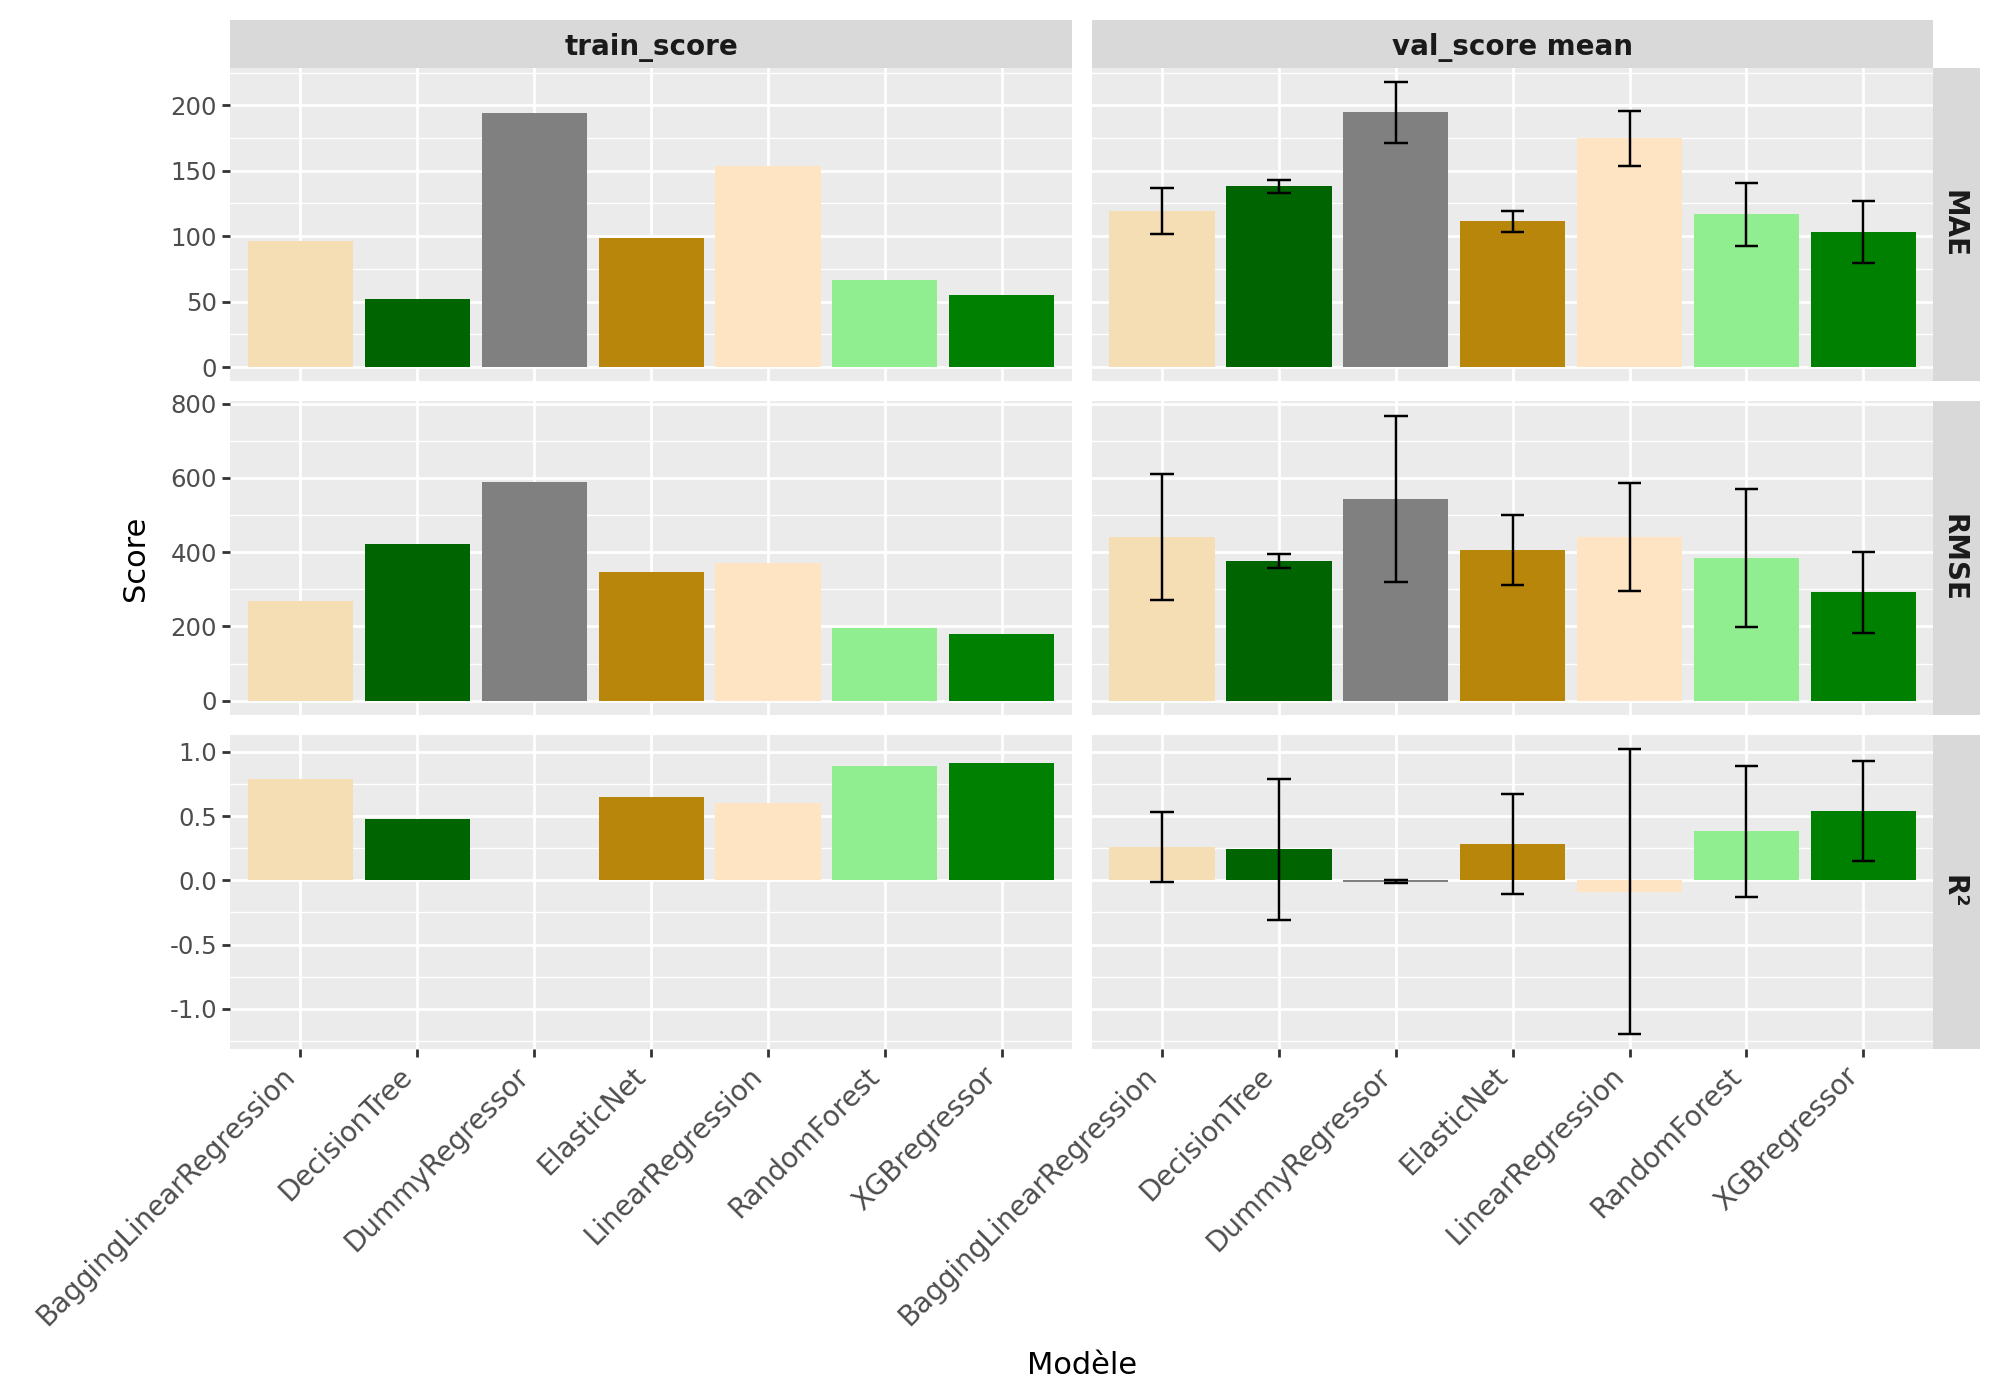

In [69]:
# Affichage du graphique présentant les résultats de la première optimisation
opt_graph(resultats)

Bien qu'ils aient une MAE et une RMSE meilleures qu'un modèle naif, les modèles linéaires ont globalement de moins bonnes performances que les autres modèles testés. La regression linéaire simple est celle qui obtient les moins bon scores de performances en validation croisée compte tenu des trois métriques analysées. L'utilisation d'une approche de bagging améliore un peu la MAE et le R² mais les scores de RMSE sont similaires à ceux obtenus avec une régression linéaire simple. Un constat similaire peut être fait lorsqu'on introduit et teste une forme de régularisation de la régression linéaire via un modèle de type ElasticNet. 

L'optimisation du modèle de la famille des arbres de décision conduit a des résultats similaires à ceux obtenus pour l'ElisticNet et la régression linéaire avec du bagging. Lorsqu'on utilise une approche de bagging sur l'arbre de décision, l'optimisation du RandomForest permet d'obtenir un meilleur R² et une meilleure MAE mais cela s'accompagne d'erreurs plus fortes avec des résultats plus variables.

Finalement, parmis tous les modèles testés, le modèle de la famille XGBRegressor semble être le plus promotteur. En effet, c'est le modèle qui obtient les meilleurs scores sur chacune des métriques en validation croisée. On obseve toutefois un overfit de ce modèle  qu'on peut essayer de réduire avec une optimisation plus fine. La variabilité des scores en validation croisée est également importante. Le but des prochaines étapes sera donc d'essayer d'améliorer davantage les performances de ce modèle tout en essayant également de réduire son overfit ainsi que sa variabilité. 

### Optimisation plus fine du XGBr

In [70]:
# Affichage des meilleurs paramètres du modèle retenu afin de cibler la plage de valeur à inclure dans la prochaine optimisation
resultats[resultats['model']=='XGBregressor']['best_model_params'].values

array(["{'regressor__max_depth': 3, 'regressor__n_estimators': 100, 'regressor__subsample': 0.8, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}",
       "{'regressor__max_depth': 3, 'regressor__n_estimators': 100, 'regressor__subsample': 0.8, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}",
       "{'regressor__max_depth': 3, 'regressor__n_estimators': 100, 'regressor__subsample': 0.8, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}"],
      dtype=object)

On va partir des paramètres optimaux identifiés lors de la première étape d'optimisation et essayer de se concentrer autour de ces valeurs pour essayer d'améliorer davantage les performances du modèle. On va de plus rajouter dans la grille de recherche différentes valeurs d'un autre paramètre important pour les modèles utilisant une approche de boosting, le learning rate.

In [71]:
# Dictionnaire des paramètres à tester pour le XGBregressor
models = {
    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [50, 100,150],
            'model__regressor__max_depth': [1,3,5],
            'model__regressor__subsample' : [0.7, 0.8, 0.9],
            'model__regressor__learning_rate' : [0.1,0.3],
            'model__transformer':Target_Transforer
        })}

# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_XGB, best_XGB, gs_XGB = optimiser_models(
    models, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : XGBregressor


In [72]:
# Affichage des résultats
resultats_XGB

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,XGBregressor,root_mean_squared_error,220.10,230.22,66.06,474.42,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.3, 'regressor__..."
1,XGBregressor,mean_absolute_error,77.60,84.72,13.08,102.07,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.3, 'regressor__..."
2,XGBregressor,r2_score,0.86,0.74,0.17,0.77,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.3, 'regressor__..."


In [73]:
# Affichage des paramètres du meilleur modèle
resultats_XGB[resultats_XGB['model']=='XGBregressor']['best_model_params'].values

array([{'regressor__learning_rate': 0.3, 'regressor__max_depth': 1, 'regressor__n_estimators': 100, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.3, 'regressor__max_depth': 1, 'regressor__n_estimators': 100, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.3, 'regressor__max_depth': 1, 'regressor__n_estimators': 100, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}],
      dtype=object)

Suite à la deuxième étape d'optimisation, les valeurs optimales des paramètres testés pour le modèle sont:
- 100 pour le nombre d'estmateurs: on va tester d'autres valeurs autour de 100
- 1 pour la profondeur : on va également tester 2
- 0.7 pour la proportion d'observations utilisée : on va tester également des valeurs plus faibles
- 0.3 pour le learning rate : on va également tester des valeurs plus faible proche de 0.3

In [74]:
# Dictionnaire des paramètres à tester pour le XGBregressor
models = {
    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [70, 100, 120],
            'model__regressor__max_depth': [1, 2],
            'model__regressor__subsample' : [0.5, 0.6, 0.7],
            'model__regressor__learning_rate' : [0.2, 0.25, 0.3],
            'model__transformer':Target_Transforer
        })}

# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_XGB, best_XGB, gs_XGB = optimiser_models(
    models, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : XGBregressor


In [75]:
# Affichage des résultats
resultats_XGB

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,XGBregressor,root_mean_squared_error,258.56,216.84,63.83,397.83,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.25, 'regressor_..."
1,XGBregressor,mean_absolute_error,72.73,85.34,12.31,92.92,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.25, 'regressor_..."
2,XGBregressor,r2_score,0.81,0.76,0.16,0.84,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.25, 'regressor_..."


In [76]:
# Affichage des paramètres du meilleur modèle
resultats_XGB[resultats_XGB['model']=='XGBregressor']['best_model_params'].values

array([{'regressor__learning_rate': 0.25, 'regressor__max_depth': 2, 'regressor__n_estimators': 100, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.25, 'regressor__max_depth': 2, 'regressor__n_estimators': 100, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.25, 'regressor__max_depth': 2, 'regressor__n_estimators': 100, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}],
      dtype=object)

Ici, les valeurs optimales des paramètres testés pour le modèle sont:
- 70 pour le nombre d'estmateurs: on va tester d'autres valeurs autour de 70
- 2 pour la profondeur : on va fixer cette valeur
- 0.7 pour la proportion d'observations utilisée : on va fixer cette valeur
- 0.3 pour le learning rate : on va également tester 0.25

Deux autres paramètres peuvent être testés pour un modèle de la famille XGBregresor. Il s'agit des paramètres de régularisation reg lambda et reg alpha. Différentes valeurs classiques pour ces paramètres vont être testées.

In [77]:
# Dictionnaire des paramètres à tester pour le XGBregressor
models = {
    'XGBregressor': (
        XGBRegressor(booster='gbtree', random_state=rdm_stt),
        {
            'Coltransfs': Coltransfs_no_lin,
            'Coltransfs_named': Coltransfs_no_lin_named,
            'model__regressor__n_estimators': [60, 70, 80],
            'model__regressor__max_depth': [2],
            'model__regressor__subsample' : [0.7],
            'model__regressor__reg_alpha':[0, 0.1, 0.5, 1],
            'model__regressor__reg_lambda':[1,5,10],
            'model__regressor__learning_rate' : [0.25],
            'model__transformer':Target_Transforer
        })}

# Liste des scores à calculer
scoring_list = [root_mean_squared_error, mean_absolute_error, r2_score]

# Appel de la fonction d'optimisation et stockage des résultats
resultats_XGB, best_XGB, gs_XGB = optimiser_models(
    models, 
    trainset[Selected_features], trainset[Variable_cible],
    testset[Selected_features], testset[Variable_cible],
    n_split=5,
    scoring_list=scoring_list,  feature_eng= group_encoder)

✅ Stratification
Optimisation du modèle : XGBregressor


In [78]:
# Affichage des résultats
resultats_XGB

,model,scoring,train_score,val_score mean,val_score std,test_score,best_coltransf,best_model_params
0,XGBregressor,root_mean_squared_error,207.14,224.38,71.54,309.51,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.25, 'regressor_..."
1,XGBregressor,mean_absolute_error,71.00,85.02,14.04,77.90,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.25, 'regressor_..."
2,XGBregressor,r2_score,0.88,0.75,0.15,0.90,ct_1_robust_none_robust_target,"{'regressor__learning_rate': 0.25, 'regressor_..."


In [79]:
# Affichage des paramètres du meilleur modèle
resultats_XGB[resultats_XGB['model']=='XGBregressor']['best_model_params'].values

array([{'regressor__learning_rate': 0.25, 'regressor__max_depth': 2, 'regressor__n_estimators': 70, 'regressor__reg_alpha': 0, 'regressor__reg_lambda': 1, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.25, 'regressor__max_depth': 2, 'regressor__n_estimators': 70, 'regressor__reg_alpha': 0, 'regressor__reg_lambda': 1, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)},
       {'regressor__learning_rate': 0.25, 'regressor__max_depth': 2, 'regressor__n_estimators': 70, 'regressor__reg_alpha': 0, 'regressor__reg_lambda': 1, 'regressor__subsample': 0.7, 'transformer': FunctionTransformer(func=<ufunc 'log1p'>, inverse_func=<ufunc 'expm1'>)}],
      dtype=object)

Suite à cette seconde phase d'optimisation, il a été possible d'améliorer les 3 scores de performances. La RMSE est passée de 292 à 224, la MAE est passé de 103 à 85 et le R² est passé de 0.57 à 0.75. La variabilité des résultats après validation croisée a également été réduite pour les 3 métriques. On observe aussi une diminution de l'overfit du modèle. 

On peut essayer d'améliorer davantage les performances du modèle retenu en utilisant une méthode de selection de variables. Pour cela, on peut utiliser une approche conssitant à selectionner les k meilleures variables selon leur importance estimée par le modèle déjà entrainé. Plusieurs valeurs de k seront testées afin d'identifier celle qui permet d'obtenir les meilleurs scores de performance.

## Selection de variables

In [80]:
# Extraction des résultats GridSearch du modèle optimisé
gs = gs_XGB['XGBregressor']  
best_params = gs.best_params_
model_name = model.__class__.__name__

# Extraction de la meilleure combinaison de transformation de features
coltransfs_named = models['XGBregressor'][1]['Coltransfs_named']
reverse_named = {v: k for k, v in coltransfs_named.items()}
Coltransf = best_params['Coltransfs']

# Extraction des hyperparamètres optimisés du modèle
model_params = {
    key.replace('model__regressor__', ''): val
    for key, val in best_params.items()
    if key.startswith('model__regressor__')
}

# Définition des paramètres fixés en dehors des paramètres à optimiser
default_params = {
    'random_state': rdm_stt,
    'booster': 'gbtree'
}

# Concaténation des paramètres optimisés et des paramètres fixés en dehors de la grille de recherche
full_model_params = {**default_params, **model_params}

# Reconstruction du modèle 
model = XGBRegressor()
model.set_params(**full_model_params)

# Extraction du transformer de la target
target_transformer = gs.best_params_['model__transformer']

In [81]:
# Initiatiolisation d'une liste pour stocker les résultats
resultats_list = []  

# Calcul du nombre de features présentes dans le jeu de données après préprocessing des features
output_n_col = Coltransf.fit_transform(trainset[Selected_features], trainset[Variable_cible]).shape[1]

for k in range(1, output_n_col + 1):
    Feat_extr = SelectFromModel(estimator=model, threshold=-np.inf, max_features=k)

    # Évaluation avec R²
    RES_a = evaluation_model(
        Coltransf, model, 
        trainset[Selected_features], trainset[Variable_cible], 
        testset[Selected_features], testset[Variable_cible],
        5, r2_score, 'R²', feat_extr=Feat_extr, target_transformer=target_transformer,
        affichage=False)

    # Évaluation avec MAE
    RES_b = evaluation_model(
        Coltransf, model, 
        trainset[Selected_features], trainset[Variable_cible], 
        testset[Selected_features], testset[Variable_cible],
        5, mean_absolute_error, 'MAE', feat_extr=Feat_extr, target_transformer=target_transformer,
        affichage=False)

    # Évaluation avec RMSE
    RES_c = evaluation_model(
        Coltransf, model, 
        trainset[Selected_features], trainset[Variable_cible], 
        testset[Selected_features], testset[Variable_cible],
        5, root_mean_squared_error, 'RMSE', feat_extr=Feat_extr, target_transformer=target_transformer,
         affichage=False)

    # Ajout de la valeur de k à chaque ligne de résultat
    for res in RES_a + RES_b + RES_c:
        res['k'] = k
        resultats_list.append(res)

# Création de la DataFrame 
resultats_feat_ext = pd.DataFrame(resultats_list)


In [82]:
# Affichage du classement des meilleurs score de MAE
resultats_feat_ext[resultats_feat_ext['scoring']=='MAE'].sort_values('val_score mean', ascending=True).head(10)

,model,scoring,train_score,val_score mean,val_score std,test_score,k
31,XGBRegressor,MAE,68.62,83.77,11.95,83.75,11
34,XGBRegressor,MAE,71.00,85.01,14.04,77.90,12
28,XGBRegressor,MAE,70.31,89.95,11.02,97.63,10
25,XGBRegressor,MAE,67.96,91.91,12.43,89.30,9
22,XGBRegressor,MAE,67.65,93.39,16.74,92.16,8
19,XGBRegressor,MAE,68.22,95.84,16.85,106.70,7
16,XGBRegressor,MAE,74.54,100.27,17.91,111.22,6
13,XGBRegressor,MAE,70.99,100.93,18.66,93.93,5
10,XGBRegressor,MAE,88.22,103.85,12.21,99.58,4
7,XGBRegressor,MAE,94.83,120.51,23.25,112.90,3


In [83]:
# Affichage du classement des meilleurs score de R²
resultats_feat_ext[resultats_feat_ext['scoring']=='R²'].sort_values('val_score mean', ascending=False).head(10)

,model,scoring,train_score,val_score mean,val_score std,test_score,k
33,XGBRegressor,R²,0.88,0.75,0.15,0.90,12
30,XGBRegressor,R²,0.89,0.73,0.19,0.88,11
21,XGBRegressor,R²,0.91,0.72,0.14,0.85,8
27,XGBRegressor,R²,0.88,0.71,0.17,0.77,10
18,XGBRegressor,R²,0.92,0.69,0.12,0.73,7
24,XGBRegressor,R²,0.90,0.67,0.12,0.87,9
12,XGBRegressor,R²,0.89,0.59,0.19,0.83,5
15,XGBRegressor,R²,0.86,0.59,0.17,0.71,6
9,XGBRegressor,R²,0.82,0.52,0.33,0.84,4
6,XGBRegressor,R²,0.79,0.43,0.21,0.77,3


In [84]:
# Affichage du classement des meilleurs score de RMSE
resultats_feat_ext[resultats_feat_ext['scoring']=='RMSE'].sort_values('val_score mean', ascending=True).head(10)

,model,scoring,train_score,val_score mean,val_score std,test_score,k
35,XGBRegressor,RMSE,207.14,224.38,71.53,309.51,12
32,XGBRegressor,RMSE,191.64,225.09,67.69,343.84,11
29,XGBRegressor,RMSE,204.71,257.50,62.09,472.76,10
23,XGBRegressor,RMSE,178.14,260.48,98.66,387.96,8
20,XGBRegressor,RMSE,170.11,275.57,91.49,517.56,7
26,XGBRegressor,RMSE,181.30,283.59,66.60,360.70,9
11,XGBRegressor,RMSE,246.01,294.93,42.28,397.25,4
17,XGBRegressor,RMSE,218.79,317.36,87.56,531.95,6
14,XGBRegressor,RMSE,192.54,325.00,96.93,409.65,5
8,XGBRegressor,RMSE,271.18,393.16,166.97,476.40,3


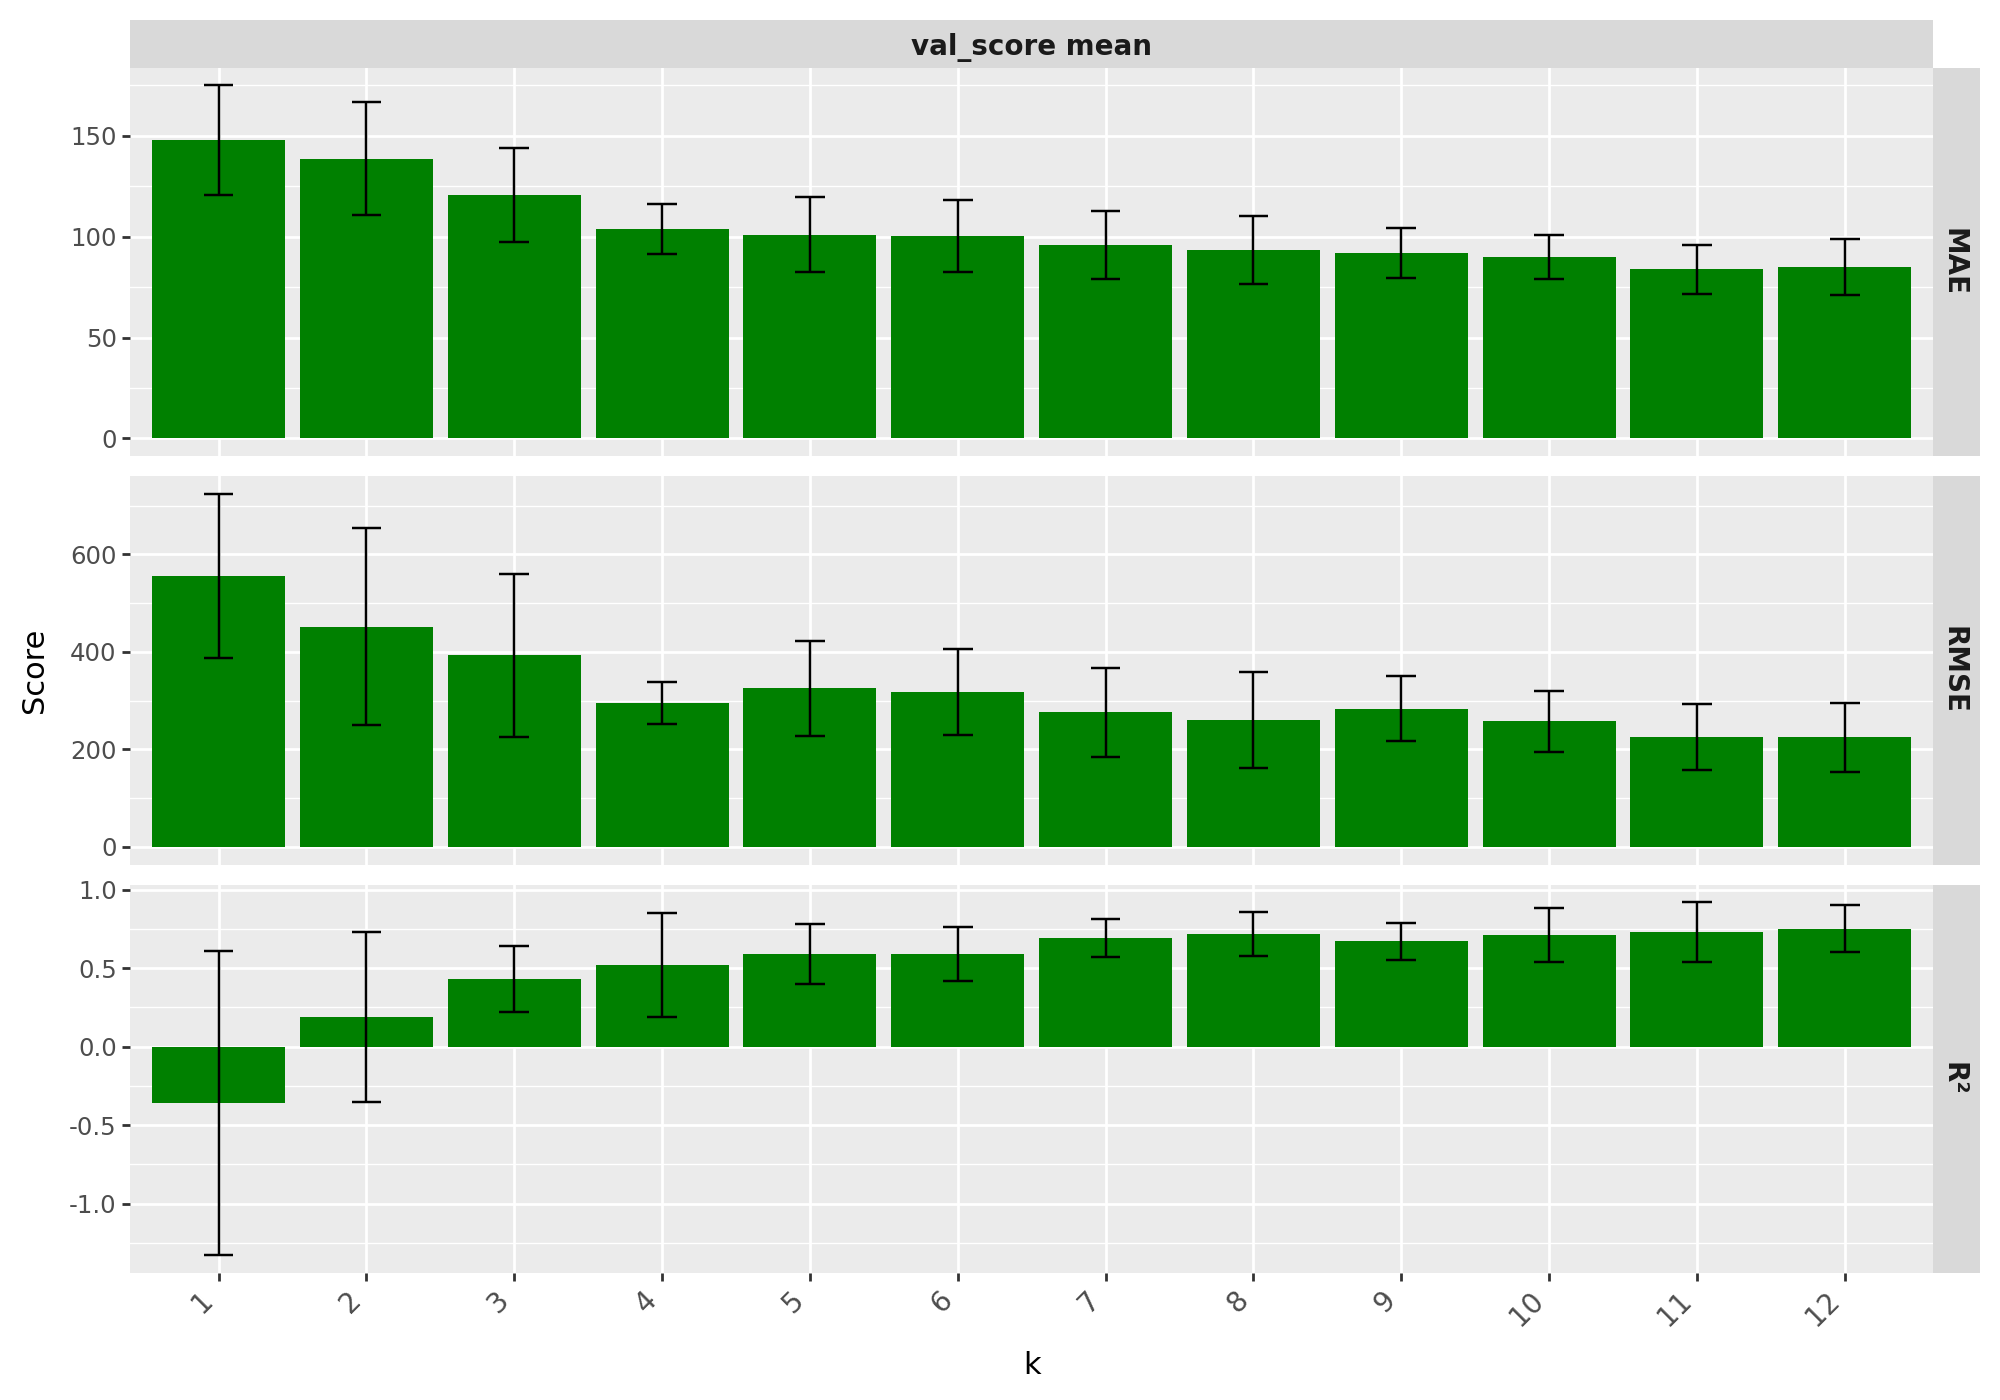

In [85]:
# Visualisation graphique des résultats
opt_graph(resultats_feat_ext, option='k')

Le test des différents k permet de conclure que le modèle a besoin de toutes les variables pour atteindre ses meilleures performances et cela s'oberve pour le R² et pour la RMSE. La meilleure MAE est obtenue quand les 11 meilleures features sont selectionnées mais selectionner toutes les variables permet d'atteindre la deuxième meilleure MAE. Le modèle final ne prendra donc pas en compte d'étape de selection de variable. 

Avant d'évaluer le modèle final de façon plus approfondie, l'impact de la variable ENERGYSTAR score va être étudié.

# Impact ENERGYSTAR

**Avec ENERGYSTAR**

In [86]:
# Définition de la méthode de selection de variable
Feat_extr = 'passthrough'

In [87]:
# Evaluation de la MAE du modèle avec ENERGYSTAR
res_with_ESS_a = evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [88]:
# Evaluation du R² du modèle avec ENERGYSTAR
res_with_ESS_b = evaluation_model(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [89]:
# Evaluation de la RMSE du modèle avec ENERGYSTAR
res_with_ESS_c =  evaluation_model(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [90]:
# Ajout d'une variable indiquant la présence ou non de la variable ENERGYSTAR
res_with_ESS = []
for res in res_with_ESS_a + res_with_ESS_b + res_with_ESS_c:
        res['ESS'] = 'Yes'
        res_with_ESS.append(res)

# Création de la DataFrame de résultat
res_with_ESS = pd.DataFrame(res_with_ESS)

**Sans ENERGYSTAR**

Pour analyser les performances du modèle sans la variable ENERGYSTAR score, il faut la retirer des variable selectionnée et de la liste de variable numériques définie pour l'étape de préprocessing. Il faudra de plus, reconstruire ces transformeurs pour pas que la variable retirée soit prise en compte.

In [91]:
# Supression de la variable ENERGYSTARscore des différentes listes
Selected_features = [x for x in Selected_features if x != 'ENERGYSTARScore'] 
num_cols = [x for x in num_cols if x != 'ENERGYSTARScore'] 

In [92]:
# Création des différentes combinaisons de préprocessing adaptées aux modèles linéaires
Coltransfs_lin_named = combined_ct(num_cols, log_cols, cat_cols, 'first')
Coltransfs_lin = [x[1] for x in Coltransfs_lin_named]
Coltransfs_lin_named = dict(Coltransfs_lin_named)

# Création des différentes combinaisons de préprocessing adaptées aux modèles non linéaires
Coltransfs_no_lin_named = combined_ct(num_cols, log_cols, cat_cols, None)
Coltransfs_no_lin = [x[1] for x in Coltransfs_no_lin_named]
Coltransfs_no_lin_named = dict(Coltransfs_no_lin_named)

In [93]:
# Définition de la méthode de selection de variable
Feat_extr = 'passthrough'

# Définition de l'étape de préprocessing
Coltransf_imp = Coltransfs_no_lin[1]

In [94]:
# Evaluation de la MAE du modèle sans ENERGYSTAR
res_wo_ESS_a = evaluation_model(Coltransf_imp, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, mean_absolute_error, 'MAE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [95]:
# Evaluation dU R² du modèle sans ENERGYSTAR
res_wo_ESS_b = evaluation_model(Coltransf_imp,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, r2_score, 'R²', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [96]:
# Evaluation de la RMSE du modèle sans ENERGYSTAR
res_wo_ESS_c =  evaluation_model(Coltransf_imp, model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 5, root_mean_squared_error, 'RMSE', feat_extr=Feat_extr, target_transformer=target_transformer,
                 affichage=None)

In [97]:
# Ajout d'une variable indiquant la présence ou non de la variable ENERGYSTAR
res_wo_ESS = []
for res in res_wo_ESS_a + res_wo_ESS_b + res_wo_ESS_c:
        res['ESS'] = 'No'
        res_wo_ESS.append(res)

# Création de la DataFrame de résultat
res_wo_ESS = pd.DataFrame(res_wo_ESS)

In [98]:
# Concaténation des deux tables de résultats
res_comparaison = pd.concat([res_with_ESS, res_wo_ESS])

#Affichage des résultats
res_comparaison

,model,scoring,train_score,val_score mean,val_score std,test_score,ESS
0,XGBRegressor,MAE,71.00,85.01,14.04,77.90,Yes
1,XGBRegressor,R²,0.88,0.75,0.15,0.90,Yes
2,XGBRegressor,RMSE,207.14,224.38,71.53,309.51,Yes
0,XGBRegressor,MAE,75.80,99.18,19.12,102.33,No
1,XGBRegressor,R²,0.86,0.68,0.13,0.79,No
2,XGBRegressor,RMSE,220.31,298.46,141.46,453.45,No


La comparaison des performances obtenues avec et sans la variable ENERGYSTAR score permet de conclure que le modèle est plus efficace avec la variable. En effet, les 3 scores utilisés pour évaluer les performances du modèles obtenus en validation croiséé sont meilleurs. Ainsi, si la variable ENERGYSTARscore n'est pas utilisée par le modèle, on observe une diminution de 9% du score R² et une augmentation de 17% de la MAE. 


Dans le cas des émissions a effet de serre, il reviendra au client de décider si la perte de performance est un compromis acceptable au vu du gain de temps apportés par la non prise en compte du score ERNERGYSTAR par le modèle. Pour la suite, j'ai vais considérer que l'on ne garde pas la variable ENERGYSTARscore car les résultats restent correctes malgré tout. 

In [99]:
# Stockage des transformations à effectuer pour le modèle sans ENERGYSTARscore
Coltransf=Coltransf_imp

# Evaluation détaillée du modèle final

En plus des fonctions d'évaluation de modèles précédemment définies, deux autres fonctions vont être définies afin de visualiser l'importance de chacune des features estimée par le modèle et de récupérer les noms des variables après l'étape de préprocessing.

## Fonction

In [100]:
def get_feature_names_from_column_transformer(coltransf, input_features):
    
    """
    Extrait la liste des noms de features produites par un `ColumnTransformer` après transformation,
    en tenant compte des différents types de transformateurs (Pipeline, passthrough, encodeurs, etc.).

    Paramètres
     - coltransf (sklearn.compose.ColumnTransformer): Le `ColumnTransformer` déjà ajusté (fit) contenant les transformations appliquées sur les colonnes.
     - input_features (list ou array-like): Liste des noms des features d'entrée avant transformation (peut être utilisée pour certaines méthodes).

    Sortie
     - list de str: Liste complète des noms des features issues du `ColumnTransformer`, dans l'ordre des colonnes transformées.

    """
    
    # Initialisation de la variable stockant les noms des features
    feature_names = []

    for name, transformer, columns in coltransf.transformers_:
        if transformer == 'passthrough':
            feature_names.extend(columns)
        elif isinstance(transformer, Pipeline):
            # Extraction du dernier step
            last_step = transformer.steps[-1][1]
            if hasattr(last_step, 'get_feature_names_out'):
                try:
                    names = last_step.get_feature_names_out(columns)
                except:
                    names = last_step.get_feature_names_out()
                feature_names.extend(names)
            else:
                feature_names.extend(columns)
        elif hasattr(transformer, 'get_feature_names_out'):
            try:
                names = transformer.get_feature_names_out(columns)
            except:
                names = transformer.get_feature_names_out()
            feature_names.extend(names)
        else:
            feature_names.extend(columns)

    return feature_names


In [101]:
def get_feature_importance_from_pipeline(Coltransf, model, Xtrain, Ytrain, 
                     feat_extr='passthrough', feature_eng=group_encoder, target_transformer=None, 
                     top_n=None):
    """
    Entraîne un pipeline complet incluant ingénierie des features, transformation, sélection de variables,
    et extraction de l'importance des variables du modèle final (compatible avec les modèles fournissant `feature_importances_`).

    Paramètres
     - Coltransf (sklearn.compose.ColumnTransformer): Transformateur des colonnes appliqué aux données.
     - model (estimator sklearn compatible): Modèle final disposant de l'attribut `feature_importances_` après entraînement (ex: XGBoost, RandomForest).
     - Xtrain (pd.DataFrame ou array-like): Données d'entraînement (features).
     - Ytrain (pd.Series ou array-like): Cible d'entraînement.
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut='passthrough')): Transformateur de sélection de variables à appliquer après `Coltransf`.
     - feature_eng (transformer, optionnel (par défaut=group_encoder)): Transformations d'ingénierie des variables à appliquer en premier dans le pipeline.
     - target_transformer (transformer ou None, optionnel (par défaut=None)): Transformateur appliqué à la cible via `TransformedTargetRegressor`.
     - top_n (int ou None, optionnel (par défaut=None)): Nombre de variables les plus importantes à afficher. Si None, affiche toutes.

    Sortie
     - pd.DataFrame: DataFrame contenant les features et leur importance, triées par ordre décroissant d'importance.
    """

    # Application d'une transformation sur la variable cible avec TransformedTargetRegressor
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

    # Pipeline
    pipeline = Pipeline([
        ('feature_engineering', feature_eng),
        ('Coltransfs', Coltransf),
        ('feature_selection', feat_extr),
        ('model', model_t)
    ])
    
    # Entrainement du pipeline
    pipeline.fit(Xtrain, Ytrain)

    # Accès au modèle final
    model_feat = pipeline.named_steps['model'].regressor_

    # Exctraction des noms de variables transformées
    coltransf = pipeline.named_steps['Coltransfs']
    feature_names = get_feature_names_from_column_transformer(Coltransf, Xtrain)

    # Application éventuelle de la sélection de variables
    feat_selector = pipeline.named_steps.get('feature_selection', None)
    if feat_selector is not None and hasattr(feat_selector, 'get_support'):
        feature_names = np.array(feature_names)
        mask = feat_selector.get_support()
        feature_names = feature_names[mask]
        
    # Extraction de la feature importance
    importances = model_feat.feature_importances_

    # Construction du DataFrame des importances
    df_importance = pd.DataFrame({
        'feature': feature_names,
        'importance': importances
    }).sort_values(by='importance', ascending=False)

    # Filtre de la table si un top_n est spécifié en argument
    if top_n:
        df_importance = df_importance.head(top_n)
    
    # Nom du modèle
    model_name = model.__class__.__name__

    # Affichage du graphique
    plt.figure(figsize=(10, 0.4 * len(df_importance)))
    plt.barh(df_importance['feature'], df_importance['importance'])
    plt.gca().invert_yaxis()
    plt.title("Top Feature Importances (XGBoost)")
    plt.tight_layout()
    plt.savefig(f'../Output/Modélisation/Explicativité/Emissions/Feature_importance {model_name}.png', format='png')
    plt.show()

    return df_importance


## Evaluation de la feature importance

Afin de mieux comprendre comment le modèle à prédit les différentes valeurs, on peut analyser l'importance des différentes features estimée par le modèle.

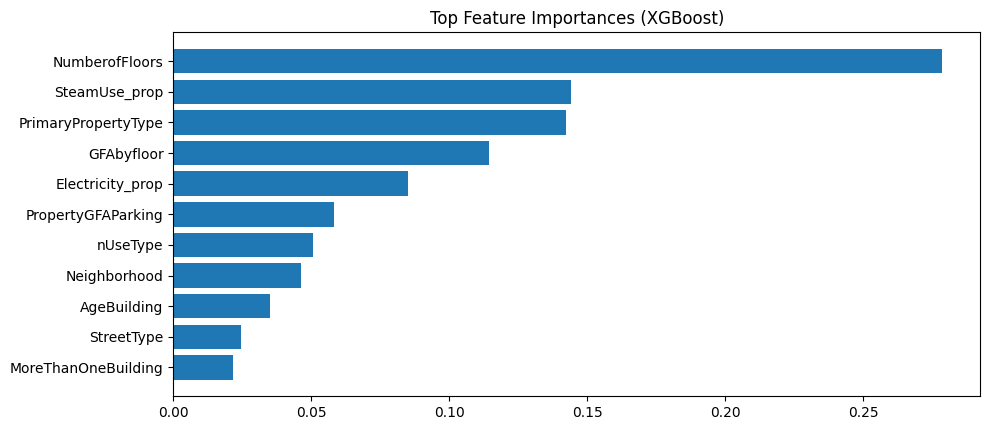

,feature,importance
0,NumberofFloors,0.278369
2,SteamUse_prop,0.144116
7,PrimaryPropertyType,0.142122
6,GFAbyfloor,0.114350
1,Electricity_prop,0.084900
5,PropertyGFAParking,0.058104
4,nUseType,0.050462
8,Neighborhood,0.046318
3,AgeBuilding,0.034982
9,StreetType,0.024604


In [102]:
# Appel de la fonction
get_feature_importance_from_pipeline(Coltransf, model, trainset[Selected_features], trainset[Variable_cible], feat_extr=Feat_extr, target_transformer=target_transformer, top_n=11)

Les features nombre d'étage, proportion de vapeur d'eau utilisée ainsi que le type de la propriété sont parmis les 3 features les plus importantes estimées par le modèle de prédiction des émissions en gaz à effet de serre. Le nombre d'étage représente à lui seul 28% de l'importance totale ce qui suggère un fort impact de cette variable. A l'inverse la variable indiquant si une propriété a un ou plusieurs bâtiments a eu un très faible impact sur les prédictions. Elle avait toutefois suffisament d'importance pour être conservée comme l'a démontré l'étape de selection de feature qui a montré que les meilleures performances étaient atteintes lorsque toutes les features étaient conservées.

## Evaluation des erreurs

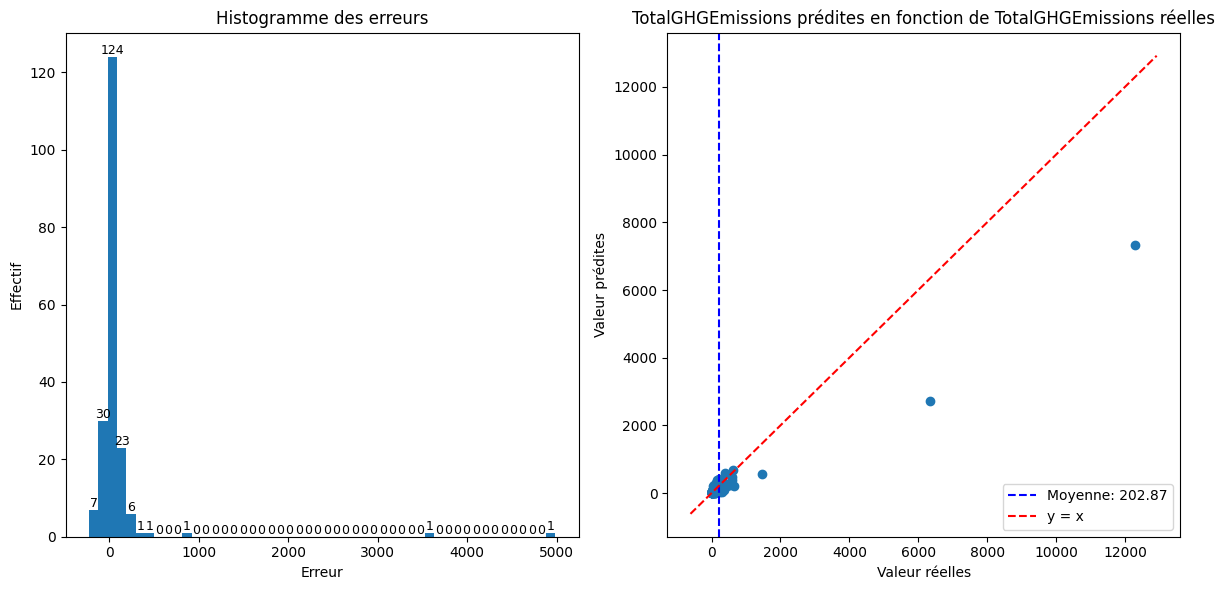

In [103]:
# Affichage des graphiques représentant les erreurs de prédiction
graph_erreur(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
             testset[Selected_features], testset[Variable_cible], feat_extr=Feat_extr, 
             target_transformer=target_transformer, Optimisation="Optimisé")

A cette échelle, on observe que, mise à part pour les propriétés avec des valeurs extrêmes en émissions de gaz à effet de serre, la majorité des points semble se situer à proximité de la droite x=y ce qui indique une bonne capacité du modèle à prédire les valeurs d'émission en gaz à effet de serre pour la plupart des propriétés. Il est néanmoins difficile de décrire précisément les résultats associés aux propriétés situées atour de la valeur moyenne. On peut zoomer sur cette partie du graphique afin de pouvoir le décrire précisément. 

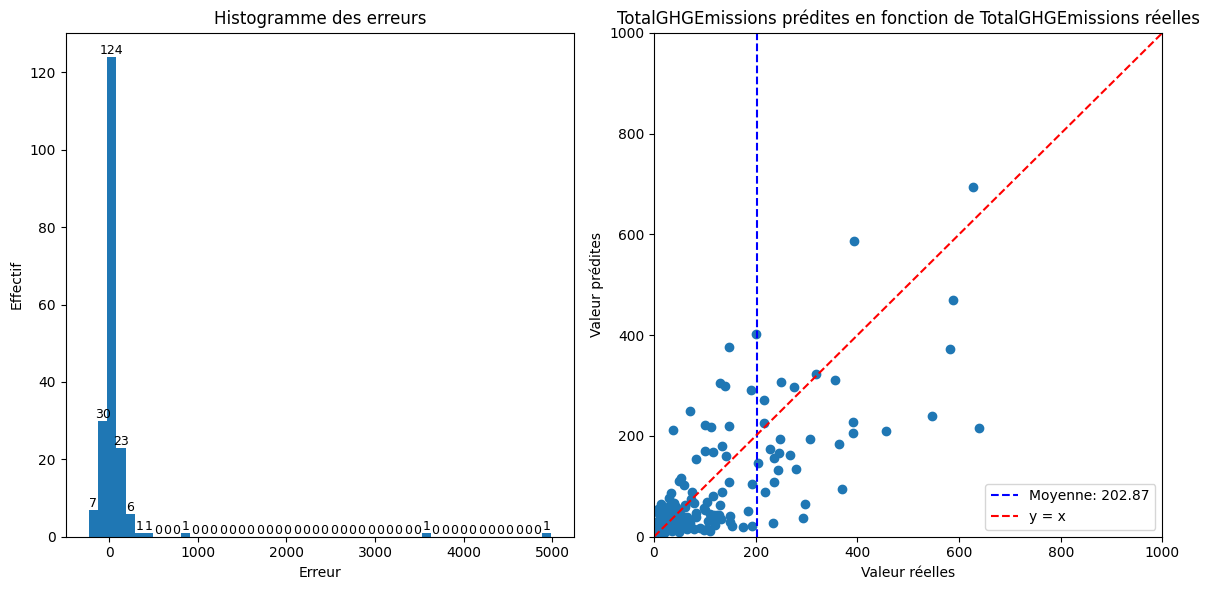

In [104]:
# Affichage des graphiques représentant les erreurs de prédiction
graph_erreur(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible], feat_extr=Feat_extr, target_transformer=target_transformer, 
                 Xlim=1000, Ylim=1000, Savefig=False)

Ici, on se rend compte que même si la plupart des points suivent la droite, on a encore des écarts plus ou moins importants entre les valeurs prédites et les valeurs réelles .

D'après l'histogramme de la distribution des erreurs, mis à part pour les 3 propriétés écartées dans le graphique de droite et pour lesquelles on a une sous-estimations très élevée, il semble y avoir a peu pres autant de sous-estimations que de sur-estimations inférieures à 500 tonnes par an. Néanmoins, il est problématique de sous-estimer à ce point les émissions pour certaines propriétés. Il est donc important d'identifier et de caractériser ces cas problématiques afin que les prédictions de ces cas soient considérées avec précaution. Pour identifier les cas pour lesquelles d'importantes erreures ont été relevée, on peut commencer par représenter les erreurs en fonction des différentes variables utilisées par le modèle.

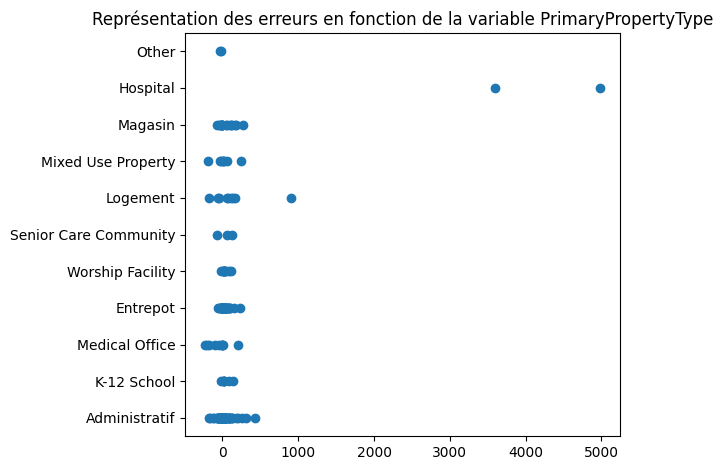

In [105]:
# Affichage du graphique représentant les erreurs de prédiction en fonction d'une variable utilisée par le modèle
graph_erreur_var(Coltransf,  model, trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible], 'PrimaryPropertyType', feat_extr=Feat_extr, target_transformer=target_transformer)

Les erreurs de prédiction les plus fortes sont obtenues pour les hopitaux. On va récupérer les index de ces bâtiments pour les explorer de façon plus approfondie. Cela pourra être fait en étudiant les valeurs shap qui permettent d'interpréter localement chaque prédiction du modèle. Les valeurs shap décomposent la prédiction de chaque observation en une somme de contribution de chaque variable, ce qui permet d'identifier les facteurs ayant le plus influencé les prédictions dans chaque cas. 

In [106]:
# Application d'une transformation sur la variable cible avec TransformedTargetRegressor
model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)

# Pipeline
pipeline = Pipeline([
        ('feature_engineering', group_encoder),
        ('Coltransf', Coltransf), 
       ('feature_selection', Feat_extr),
        ('model', model_t) 
    ])
    
# Entraînement du modèle sur l'ensemble complet d'entraînement 
pipeline.fit(trainset[Selected_features], trainset[Variable_cible])
        

# Prédiction des résultats sur le jeu de train et de test
test_predictions = pipeline.predict( testset[Selected_features])
    
# Calcul de l'erreur
testset['err_hist'] = testset[Variable_cible]- test_predictions

# Affichage de la dataframe
testset.sort_values('err_hist')

,PrimaryPropertyType,Neighborhood,NumberofFloors,PropertyGFAParking,ENERGYSTARScore,TotalGHGEmissions,StreetType,Electricity_prop,SteamUse_prop,GFAbyfloor,MoreThanOneBuilding,AgeBuilding,nUseType,Target_cat,err_hist
178,Medical Office,East,14,407795,58.0,147.49,other,1.000000,0.000000,20168.785714,False,24,2,Category_4,-229.209615
177,Medical Office,East,3,104000,65.0,201.15,Street,0.855604,0.034269,54000.000000,False,71,2,Category_5,-200.809503
840,Mixed Use Property,Downtown,19,201857,87.0,393.29,Avenue,0.843195,0.000000,52884.894737,False,7,4,Category_5,-192.941506
334,Administratif,Downtown,3,0,77.0,70.09,Way,1.000000,0.000000,62376.666667,False,23,6,Category_3,-179.613033
314,Medical Office,East,9,101342,58.0,130.32,Avenue,0.959620,0.000000,22395.555556,False,8,2,Category_4,-174.759407
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118,Administratif,Downtown,42,171500,28.0,546.65,Avenue,0.987299,0.012701,10623.428571,False,43,4,Category_5,306.867422
370,Administratif,Downtown,27,13320,62.0,639.72,Avenue,0.535807,0.456348,7527.814815,False,87,3,Category_5,423.351683
162,Logement,Downtown,19,59280,6.0,1468.50,Avenue,0.524024,0.412486,14357.210526,False,43,1,Category_5,909.416748
962,Hospital,East,8,0,74.0,6330.91,Street,0.549330,0.450670,46808.250000,False,96,1,Category_5,3601.718594


In [107]:
# Stackage des index correspondant aux propriétés dont l'erreur de prédiction des consommation est la plus sous estimée
index_high_error = testset[testset['err_hist']>500].index

## Analyse shap

### Fonction

In [108]:
def get_shap_values(Coltransf, model, Xtrain, Ytrain, Xtest, Ytest, feat_extr='passthrough', feature_eng=group_encoder, target_transformer=FunctionTransformer()):
    
    """
    Calcule les valeurs SHAP pour un modèle entraîné dans un pipeline comprenant ingénierie de features,
    transformations, sélection de variables, et un `TransformedTargetRegressor` appliqué sur la cible.

    Paramètres
     - Coltransf (sklearn.compose.ColumnTransformer): Transformations appliquées aux colonnes (ex: normalisation, encodage).
     - model (estimator sklearn compatible): Modèle final à expliquer (doit avoir une méthode `predict`).
     - Xtrain (pd.DataFrame): Jeu d'entraînement (features brutes).
     - Ytrain (pd.Series ou array-like): Cible d'entraînement.
     - Xtest (pd.DataFrame): Jeu de test (features brutes).
     - Ytest (pd.Series ou array-like): Cible de test (non utilisé dans la fonction mais présent pour cohérence).
     - feat_extr (transformer ou 'passthrough', optionnel (par défaut='passthrough')): Sélection de variables appliquée après transformation des colonnes.
     - feature_eng (transformer, optionnel (par défaut=group_encoder)): Transformation d'ingénierie des variables appliquée en premier.
     - target_transformer (transformer, optionnel (par défaut=FunctionTransformer())): Transformateur appliqué à la cible via `TransformedTargetRegressor`.

    Sortie
     - shap_values_train (shap._explanation.Explanation): Valeurs SHAP calculées sur le jeu d'entraînement.
     - shap_values_test (shap._explanation.Explanation): Valeurs SHAP calculées sur le jeu de test.
     - train_transformed_df (pd.DataFrame): Données d'entraînement transformées et sélectionnées (features finales).
     - test_transformed_df (pd.DataFrame): Données de test transformées et sélectionnées (features finales).
     - explainer (shap.Explainer): Explainer SHAP utilisé pour le calcul.
    """

    # Application des premières étapes de la pipeline : feature engineering
    train_engineering = group_encoder.fit_transform(Xtrain)
    test_engineering = group_encoder.transform(Xtest)

    # Application des premières étapes de la pipeline : preprocessing
    train_transformed = Coltransf.fit_transform(train_engineering, Ytrain)
    test_transformed = Coltransf.transform(test_engineering)
    
    # Extraction des index des jeux de données d'entrainement et de test
    index_train = Xtrain.index
    index_test = Xtest.index
        
    #train_transformed = train_transformed.toarray()
    #test_transformed = test_transformed.toarray()
    
    # Application des premières étapes de la pipeline : selection de feature + Extraction des noms des variables
    if feat_extr != 'passthrough':
        train_selection = Feat_extr.fit_transform(train_transformed, Ytrain)
        test_selection = Feat_extr.transform(test_transformed)
        all_feature_names = get_feature_names_from_column_transformer(Coltransf, train_engineering.columns)
        mask = Feat_extr.get_support()  
        selected_columns = [name for name, keep in zip(all_feature_names, Feat_extr.get_support()) if keep]
    else :
        train_selection = train_transformed
        test_selection = test_transformed
        selected_columns = get_feature_names_from_column_transformer(Coltransf, train_engineering.columns)
        

    # Conversion en DataFrame 
    train_transformed_df = pd.DataFrame(train_selection, columns=selected_columns, index=index_train)
    test_transformed_df = pd.DataFrame(test_selection, columns=selected_columns, index=index_test)

    # Entraînement du modèle 
    model_t = TransformedTargetRegressor(regressor=model, transformer=target_transformer)
    model_t.fit(train_transformed_df, Ytrain)

    # Calcul des valeurs SHAP
    explainer = shap.Explainer(model_t.regressor_.predict, train_transformed_df)
    shap_values_train = explainer(train_transformed_df)
    shap_values_test = explainer(test_transformed_df)

 
    return shap_values_train, shap_values_test,  train_transformed_df, test_transformed_df, explainer


### Analyse

In [109]:
# Appel de la fonction et stockage des résultats
shap_val_train, shap_val_test, train_transf, test_transf, expl = get_shap_values(
                 Coltransf, model,
                 trainset[Selected_features], trainset[Variable_cible], 
                 testset[Selected_features], testset[Variable_cible],
                 feat_extr=Feat_extr, feature_eng=group_encoder)

PermutationExplainer explainer: 779it [00:57, 11.74it/s]                                                               
PermutationExplainer explainer: 196it [00:13,  3.37it/s]                                                               


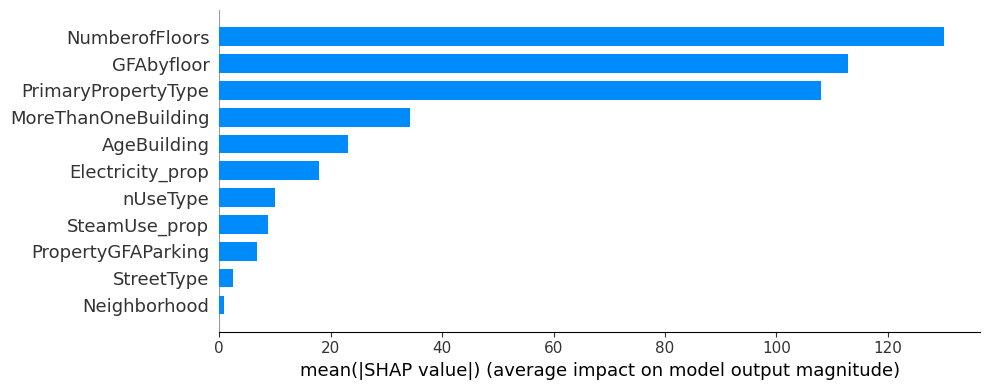

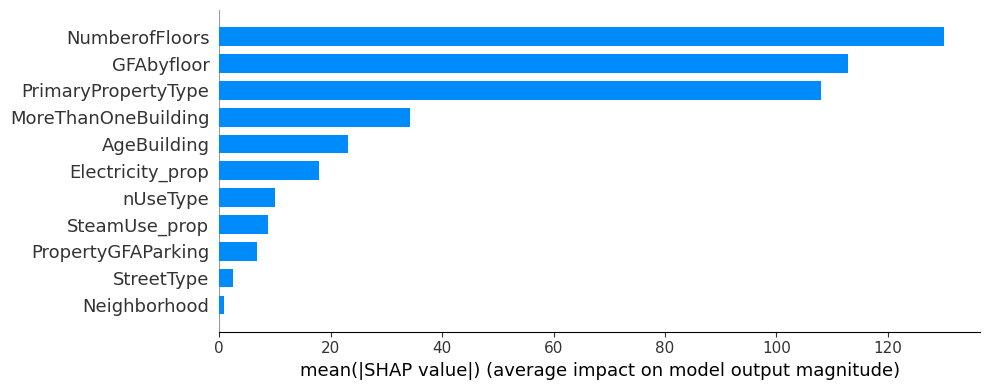

In [110]:
# Désactivation des warnings de type Futur pour plus de lisibilité
warnings.simplefilter(action='ignore', category=FutureWarning)

# Extraction du nom du modèle
model_name = model.__class__.__name__

# Visualisation et sauvegarde du plot SHAP global test
shap.summary_plot(shap_val_test, test_transf, plot_type="bar", plot_size=(10, 4))
plt.tight_layout()
plt.close() 

# Visualisation et sauvegarde du plot SHAP global train
shap.summary_plot(shap_val_test, train_transf, plot_type="bar", plot_size=(10, 4))
plt.tight_layout()
plt.close()

In [111]:
# Désactivation des warnings de type Futur pour plus de lisibilité
warnings.simplefilter(action='ignore', category=FutureWarning)

# Extraction du nom du modèle
model_name = model.__class__.__name__

# Visualisation et sauvegarde du plot SHAP global test
shap.summary_plot(shap_val_test, test_transf, plot_type="bar", plot_size=(10, 4), show=False)
plt.tight_layout()
plt.savefig(f"../Output/Modélisation/Explicativité/Emissions/shap_summary_test - {model_name}.png", dpi=300, bbox_inches='tight')
plt.close() 

# Visualisation et sauvegarde du plot SHAP global train
shap.summary_plot(shap_val_test, train_transf, plot_type="bar", plot_size=(10, 4), show=False)
plt.tight_layout()
plt.savefig(f"../Output/Modélisation/Explicativité/Emissions/shap_summary_train - {model_name}.png", dpi=300, bbox_inches='tight')
plt.close()

Les summary plot générés par SHAP représentent la contribution moyenne des différentes feature dans la prédiction des valeurs de la consommation énergétique. On retrouve un ordre global similaire à celui obtenu par l'anlyse de la feature importance classique implanté dans sickit learn. Le nombre d'étage reste la variable qui contribue le plus à la prédiction.Quelques variations dans le classement apparaissent mais celles ci sont minimes. Pour aller plus loin dans l'analyse de la contribution des features on peut également regarder dans quelle direction les différentes features ont impacté sur les valeurs prédites. 

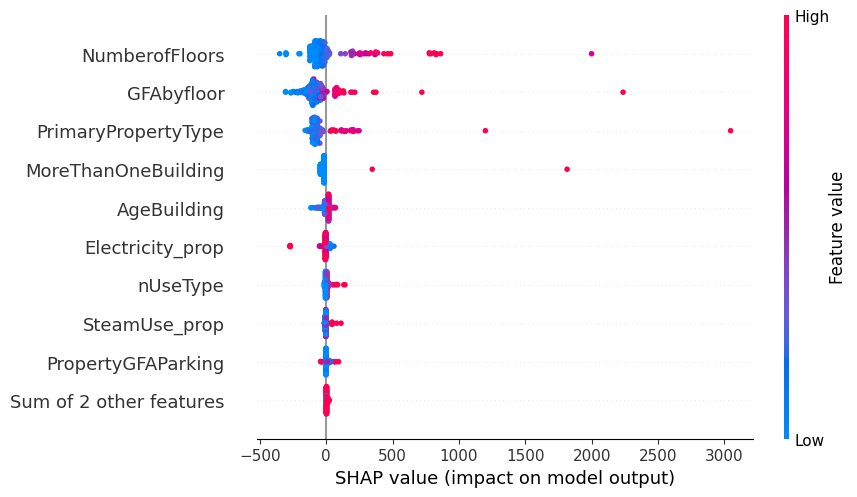

In [112]:
# Création d'une nouvelle figure
plt.figure(figsize=(10, 4))

# Affichage du plot SHAP beeswarm
shap.plots.beeswarm(shap_val_test)

In [113]:
# Création d'une nouvelle figure
plt.figure(figsize=(10, 4))

# Affichage du plot SHAP beeswarm
shap.plots.beeswarm(shap_val_test, show=False)

# Sauvegarde
plt.savefig(f"../Output/Modélisation/Explicativité/Emissions/shap_beeswarm_test -  {model_name}.png", dpi=300, bbox_inches='tight')

# Fermeture de la figure la figure
plt.close()

On remarque alors que  les propriétés avec un nombre d'étage élevé ont tendance à avoir des valeurs SHAP positives et élevées ce qui signifie qu'elles contribuent à augmenter la valeur des émissions en gaz à effet de serre pédites par le modèle. Autrement dit plus une propriété a un nombre d'étage élevé plus la valeur prédite est également élevée. Les même observations peuvent être faites pour la surface par étage. Afin de mieux comprendre les prédictions d'un cas spécifique on peut utiliser les valeurs SHAP pour regarder localement pour une propriété donnée la contribution de chacune des features dans la prédiction. On va regarder quelques exemples de propriétés dont la consommation énergétique été prédite avec une forte sous estimation. On va s'intéresser aux propriétés précédemment sauvegarder dans index_high_error

In [114]:
# Affichage des index correspondant aux propriété dont la consommation a été fortement sous estimée
index_high_error

Index([162, 404, 962], dtype='int64')

PrimaryPropertyType         Hospital
Neighborhood                    East
NumberofFloors                    14
PropertyGFAParking                 0
ENERGYSTARScore                 54.0
TotalGHGEmissions           12307.16
StreetType                     other
Electricity_prop            0.477874
SteamUse_prop               0.462746
GFAbyfloor             126140.714286
MoreThanOneBuilding             True
AgeBuilding                       22
nUseType                           2
Target_cat                Category_5
err_hist                 4985.175625
Name: 404, dtype: object


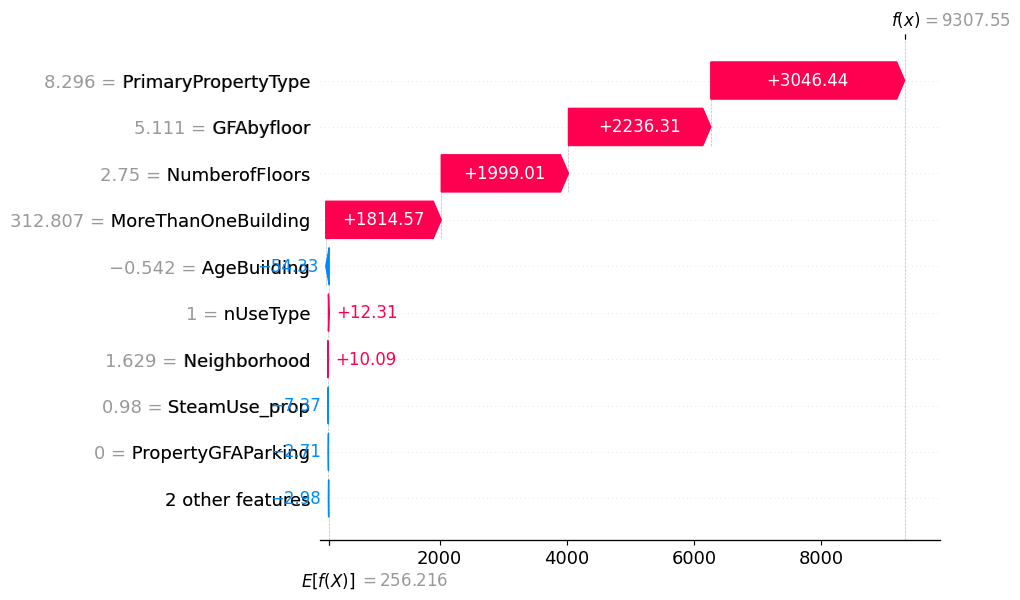

In [115]:
# Exctration de la position dans le jeu de données et affichage de ses caractéristiques brutes
position = testset.index.get_loc(404)
print(testset.loc[404])

# Visualisation des contributions locales des variables utilisées dans le modèle
shap.plots.waterfall(shap_val_test[position])

# Sauvegarde
plt.savefig(f"../Output/Modélisation/Explicativité/Emissions/shap_waterfall_404 - {model_name}.png", dpi=300, bbox_inches="tight")

# Fermeture de la figure
plt.close()

In [116]:
# Création d'une nouvelle figure
plt.figure(figsize=(10,4))           

# Visualisation des contributions locales des variables utilisées dans le modèle
shap.plots.waterfall(shap_val_test[position], show=False)

# Sauvegarde
plt.savefig(f"../Output/Modélisation/Explicativité/Emissions/shap_waterfall_404 - {model_name}.png", dpi=300, bbox_inches="tight")

# Fermeture de la figure
plt.close()

Ici on peut voir que les variables qui ont le plus contribué à diminuer la prédiction des valeurs des émissions en gaz a effet de serre de cette propriété sont les variables de l'âge de la propriété, de la proportion de vapeur d'eau utilisée et de la surface en parking. Néanmoins ces variables n'ont que faiblement contribué à la diminution des valeurs prédites par le modèle. Toutefois, il faut rappeler que cette propriété correspond à un hopital. Il est donc probable que d'autres caractéristiques spécifiques à ce type d’établissement et pouvant être variables d'un hôpital à un autre n’aient pas été présentes dans les données disponibles, et n’aient donc pas pu être prises en compte dans la modélisation ce qui pourrait expliquer en partie l’écart entre la prédiction du modèle et la consommation réellement observée.

PrimaryPropertyType        Logement
Neighborhood               Downtown
NumberofFloors                   19
PropertyGFAParking            59280
ENERGYSTARScore                 6.0
TotalGHGEmissions            1468.5
StreetType                   Avenue
Electricity_prop           0.524024
SteamUse_prop              0.412486
GFAbyfloor             14357.210526
MoreThanOneBuilding           False
AgeBuilding                      43
nUseType                          1
Target_cat               Category_5
err_hist                 909.416748
Name: 162, dtype: object


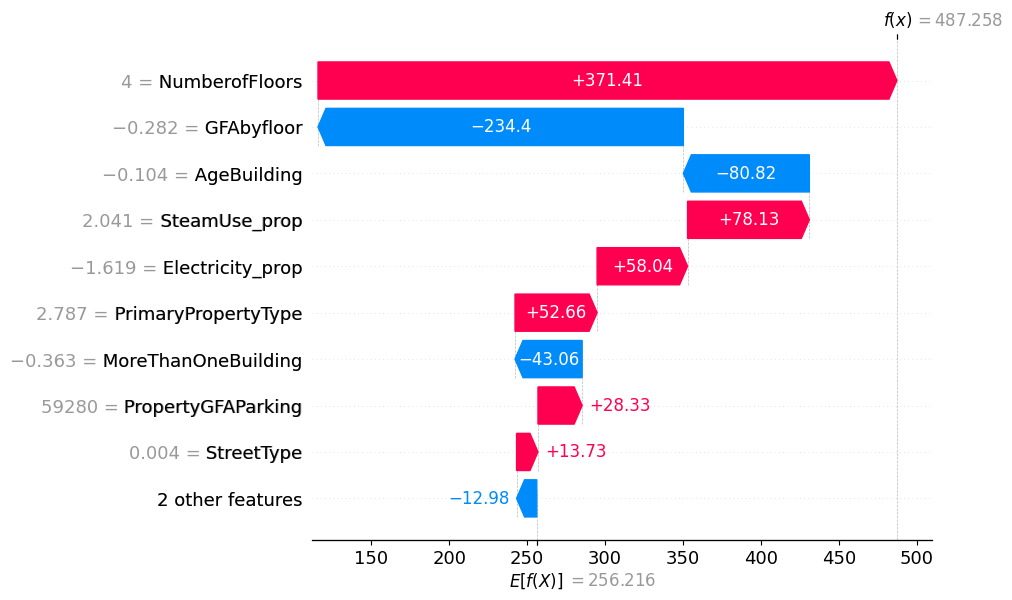

In [117]:
# Exctration de la position dans le jeu de données et affichage de ses caractéristiques brutes
position = testset.index.get_loc(162)
print(testset.loc[162])

# Visualisation des contributions locales des variables utilisées dans le modèle
shap.plots.waterfall(shap_val_test[position])

# Fermeture de la figure
plt.close()

In [118]:
# Création d'une nouvelle figure
plt.figure(figsize=(10,4))           

# Visualisation des contributions locales des variables utilisées dans le modèle
shap.plots.waterfall(shap_val_test[position], show=False)

# Sauvegarde
plt.savefig(f"../Output/Modélisation/Explicativité/Emissions/shap_waterfall_162 - {model_name}.png", dpi=300, bbox_inches="tight")

# Fermeture de la figure
plt.close()

Ici, c'est principalement la surface par étage suivi de l'âge de la propriété qui le plus joué sur la diminution de la valeur d'émissions en gaz à effet de serre prédite par le modèle. 

Comme évoqué précédemment, il est ici également très probable que d'autres facteurs non présents dans le jeu de données et donc non pris en compte dans le modèle comme l'isolation des bâtiments aient pu jouer dans ces erreurs de prédiction. Il pourrait être intéressant de revenir sur les cas où les valeurs ont été fortement sous estimées afin de déterminer s'ils correspondent à des bâtiments particulièrement mal isolés ou présentant d'autres caractéristiques spécifiques non intégrées dans le modèle. D'autres facteurs exogènes comme les comportements humains peuvent également impacter les émissions en gaz à effet de serre. Enfin  il n'est pas exclu que malgrés le nettoyage des données effectué précédemment certaines valeurs présentes dans le jeu de données utilisées soient restées éronnées ou mal renseignées ce qui pourrait fausser la prédiction des valeurs de ces bâtiments.

# Conclusions

Ce projet avait pour objectif de modéliser la consommation énergétique et les émissions en gaz a effet de serre des bâtiments non résidentiels de la ville de Seattle dans le cadre de la transition écologique engagé par la ville. Il s'agissait également d'évaluer l'impact du score ENERGYSTAR sur les performances des modèles mis en place. 

Concernant la modélisation des émissions en gaz à effet de serre présentée ici, plusieurs approches ont été testées allant de modèles linéaires simples à des modèles plus complexes comme le RandomForest ou le XGBregressor. Une phase d'optmisation par recherche en grille a permis d'ajuster à la fois les hyperparamètres des différents modèles testés et les stratégies de prétraitement des données (normalisation, encodages des variables catégorielles...). 

Le modèle final retenu est un XGBregressor. Ce modèle a montré de bonne capacité de généralisation avec des performances satisfaisantes sur le jeu de test malgrés certaines erreurs importantes sur des cas spécifiques. L'analyse des erreurs et des contributions de variable a permis d'identifier ces cas spécifiques pour lesquels certaines caractéristiques sont peut être manquantes. En effet, les propriétés dont l'émission en gaz à effet de serre à été le plus sous estimée correspondent à des hopitaux. Ce type de propriété peut avoir des caractéristiques non couvertes par les données ce qui pourrait expliquer les erreurs de prédictions qui leur sont associées. Pour ce type de propriété le modèle mis en place ici ne sera peut être pas adapté. Enfin, bien que le score ENERGYSTAR ait permis une amélioration des performances, son inclusion dans le modèle devra être discuté avec le client qui choisira le meilleur compromis entre perte de performance et gain de temps. Les scores de performances obtenus restant correctes, il pourrait être avantageux de l'exclure au vu de la difficulté d'obtention de ce score.